# Section 5 : Vers une exploitation de la donnée  : précautions et outils

## Présentation de la section

#### Installation

Les fichiers relatifs à cette section se trouvent sous le répertoire plido-tp6. Faites un git pull avant de commencer pour resynchroniser les répertoires.

#### Présentation de la section

L’exploitation des données de type *mesure,* remontées par les objets connectés, sera abordée durant cette section au travers de la visualisation et de l’analyse de cette remontée d’informations.

Il s’agira notamment de sensibiliser et de reconnaitre les distorsions pouvant apparaitre dans la série de données associées à un capteur lors de son suivi.

Ce sera l’occasion de voir, au travers de différents exemples, certaines grandeurs caractérisant le signal reçu. Quelques concepts et outils mathématiques de base sont nécessaires pour manipuler ces grandeurs. Ils seront introduits brièvement dans ce contexte des objets connectés en lien avec la donnée mesurée.

À la fin de cette section, vous serez capable :

-        de comprendre la restitution graphique des données mesurées,

-        d’appliquer quelques traitements de base pour comprendre certains biais liés aux données reçues,

-        d’exprimer les risques associés à une surinterprétation des données reçues.

### Problématiques de l'utilisation des données IoT - Quiz 5.1

#### Vidéo : Problématiques d'utilisation des données de l'IoT

# **Vidéo : Problématiques d'utilisation des données de l'IoT**

#### Texte : Problématiques d'utilisation des données de l'IoT

Les précédentes sections ont présenté les technologies et protocoles de l’internet des Objets. Elles ont montré comment les capteurs pouvaient faire parvenir à l’utilisateur des données mesurées dans leur environnement. Supposons donc que tout va bien et qu’on a reçu des données. Les stocker dans une base de données, c'est bien, mais pouvoir appliquer un traitement c'est encore plus utile. On peut penser à deux usages principaux des données :

* l’utilisation la plus simple, c’est juste une visualisation : on veut fournir à l’utilisateur des voyants, des courbes qu’il pourra consulter. On l'a fait avec *Beebotte* mais sans réellement appliquer de traitement à la donnée. On transformait juste sa représentation pour la rendre compatible avec le service. Déjà, si les données reçues ont l’air assez chaotiques, il va falloir se demander si on les représente telles quelles ou si on leur applique un traitement, par exemple une sorte de lissage, ou encore si on supprime des valeurs qui semblent aberrantes ;

* là où les choses se compliquent, c’est lorsqu’on veut utiliser les données reçues pour prendre une décision, comme arroser automatiquement les plantes en fonction de mesures d’humidité, lancer le chauffage ou la climatisation à partir de mesures de température, ou encore lancer une alarme à partir de mesures de qualité de l’air. Dans tous ces cas, il est crucial de chercher à prendre la meilleure décision car cela peut avoir des conséquences en termes de coût, d’impact environnemental, ou de sécurité. Il faut donc bien être conscient du processus qui a conduit à l’obtention des données, et le prendre en compte pour effectuer les traitements les plus appropriés dans la prise de décision.

Ce sont ces précautions sur la prise en compte des données reçues, et quelques outils de traitement des données brutes, qu’on va aborder dans cette section. Pour préciser les choses, on peut définir un modèle mathématique qui représente les données brutes qu’on reçoit. On utilisera ce modèle pour évaluer la confiance qu’on peut avoir en ces données, ou quantifier l’effet d’un traitement, par exemple calculer la probabilité de se tromper lorsqu’on prend une décision.

**Quiz : Quiz 5.1**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Etant donné la valeur reçue à la date \(t_1\), est-il judicieux d'arroser la plante ?**"))
q0_w = widgets.RadioButtons(options=["ouiObserver la tendance générale des données : pourrait-il s'agir d'une erreur de mesure ?", "nonEn effet, la valeur en question semble être une anomalie, peut-être issue d'une erreur de mesure, car l'humidité revient dans la zone normale juste après. De plus, ici le risque associé à une erreur (non-arrosage, ou arrosage un peu tardif) n'est pas très élevé"], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == "nonEn effet, la valeur en question semble être une anomalie, peut-être issue d'une erreur de mesure, car l'humidité revient dans la zone normale juste après. De plus, ici le risque associé à une erreur (non-arrosage, ou arrosage un peu tardif) n'est pas très élevé", ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**Etant donné la valeur reçue à la date \(t_1\), est-il judicieux de lancer une alerte incendie ?**"))
q1_w = widgets.RadioButtons(options=["ouiEn effet, la valeur en question ne semble pas être une anomalie mais plutôt traduire une tendance (bien qu'étant légèrement au-dessus de la tendance). De plus, ici le risque associé à une erreur de non-alerte est très élevé : s'il y a un incendie il faut alerter le plus rapidement possible, quitte à avoir de temps en temps de fausses alertes.", "nonObserver la tendance générale des données : s'agit-il d'une erreur de mesure, ou bien y a-t-il vraiment un problème de fumée ? Egalement, quel est le coût d'une fausse alarme versus une alerte manquée ?"], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == "ouiEn effet, la valeur en question ne semble pas être une anomalie mais plutôt traduire une tendance (bien qu'étant légèrement au-dessus de la tendance). De plus, ici le risque associé à une erreur de non-alerte est très élevé : s'il y a un incendie il faut alerter le plus rapidement possible, quitte à avoir de temps en temps de fausses alertes.", ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)



## Comprendre les données reçues

### Modélisation mathématique des données reçues

#### Vidéo : Modélisation mathématique des données reçues

# **Vidéo : Modélisation mathématique des données reçues**

Pour savoir quelle confiance on peut avoir en une donnée, il faut comprendre  comment elle nous est parvenue.

On va donc ici chercher à construire un modèle mathématique qui représente l’ensemble du processus conduisant à la réception des données. Il y a principalement deux grandes étapes qu’on peut séparer : la mesure effectuée par le capteur, et la transmission jusqu’à l’utilisateur.

Modélisons d’abord **la mesure** que le capteur effectue, et qu’on va noter M. Cette mesure n’est pas nécessairement exactement égale à la valeur réelle de la grandeur physique qui nous intéresse, et qu’on va noter V, comme « **vraie valeur** ». En effet :

* il se peut que le capteur ne soit pas à l’endroit idéal pour faire la mesure : pour mesurer la température d’une pièce, la valeur sera surestimée si le capteur est au plafond, et sous-estimée s'il est au sol ;
* le capteur peut également avoir un défaut, un biais de mesure qui le conduit à systématiquement surestimer ou sous-estimer la grandeur à mesurer. Le biais pourrait même varier selon la valeur de la grandeur, par exemple un capteur de température pourrait la surestimer lorsqu’il fait froid et la sous-estimer lorsqu’il fait chaud, mais on va prendre ici un modèle simple, où le biais ne dépend pas de la vraie valeur V

Ces deux effets conduisent à un **biais** systématique, qu’on va noter b. On peut supposer qu’on le connait (auquel cas on pourra simplement le soustraire à la réception), ou bien qu’il soit inconnu et qu’on pourra chercher à l’évaluer. La valeur de ce biais b correspond à ce qu’on appelle le **défaut de justesse**.

Il peut aussi y avoir des variations d’une mesure à l’autre, même si rien n’a changé apparemment. On le constate lorsqu’on prend sa température ou qu’on se pèse plusieurs fois de suite sur une balance numérique : la valeur indiquée peut varier un peu. Pour représenter cela, on va introduire une autre valeur, qu’on va traiter comme une variable aléatoire car elle change à chaque mesure, et qui en moyenne vaut 0 (sinon, cette valeur moyenne serait à intégrer au biais b). Notons cette variable aléatoire avec la lettre N, comme « noise » en anglais, car il s’agit de ce qu’on appelle un bruit de mesure. Pour quantifier l’amplitude de ce **bruit**, on utilise l’écart-type de la variable N, qui peut s’estimer à partir d’un ensemble de mesures indépendantes avec cette formule. Cela s’appelle le **défaut de fidélité**.

On se retrouve donc avec une formulation où la valeur mesurée M par le capteur est bien sûr liée à la vraie valeur V qu’on recherche, mais à cause du défaut de justesse b et du défaut de fidélité, M n’est pas exactement égal à V. La différence, somme donc du biais et du bruit de mesure, s’appelle le défaut d’exactitude.

Enfin, soulignons que la précision du résultat peut aussi avoir un effet : si notre capteur de température n’utilise que des nombres entiers pour les degrés, il ne nous dira pas qu’il fait 18,4°. Il y a alors une **discrétisation** qui est effectuée, pour que l’information à transmettre soit dans l’ensemble autorisé (par exemple les entiers). A l’extrême, l’information envoyée pourrait être binaire, du type « il y a du soleil » ou « il n’y a pas de soleil » à partir d’un capteur de lumière.

Voilà donc pour l’aspect « mesure », à l’origine de la donnée fournie par le capteur. Pour que cette donnée parvienne à l’utilisateur, il y a encore deux aspects importants à prendre en compte : l’aspect temporel, et la transmission proprement dite.

* Tout d’abord, l’aspect temporel, concernant la mesure et sa transmission : quand cette mesure a-t-elle été prise ? Et quand a-t-elle été envoyée ? Certains capteurs prennent des mesures de façon régulière, mais ne les transmettent que rarement, en regroupant plusieurs mesures dans un seul paquet, envoyé une fois par jour ou une fois par semaine. C'est ce que nous avons fait avec Beebotte avec l'utilisation de séries temporelles. Cela peut avoir un impact, notamment si on veut visualiser une quantité en temps réel ou prendre des décisions rapidement.
* Une autre politique d’émission consiste à n’envoyer des données que lorsqu’un événement particulier survient, par exemple lorsque la température dépasse un certain seuil. Nous l'avons utilisée au moment de stocker les données dans la base mongodb en émettant périodiquement les valeurs de température, pression et humidité.
* Enfin, pour la transmission, il ne faut pas oublier que des problèmes peuvent survenir, à cause d’interférences radio, d’une trop faible puissance d’émission, ou pour une autre raison. Dans ce cas, grâce aux protocoles utilisés le récepteur ne va pas prendre en compte une valeur qui aurait été modifiée par des erreurs de transmission, car ces erreurs sont détectées. Mais les paquets affectés seront simplement ignorés. La conséquence, ce sont donc non pas des valeurs mal transmises, mais simplement des valeurs manquantes. Une façon assez simple de modéliser cela est d’introduire une probabilité d’erreur de transmission, qui devra prendre en compte l’aspect temporel évoqué avant, car si plusieurs données sont regroupées dans un seul envoi, elles seront toutes perdues en cas d’erreur de transmission.

En résumé, les données brutes reçues peuvent être sujettes à des erreurs de mesure, subir des délais avant d’être transmises, et être perdues lors de la transmission. Il faudra être conscient de tout cela lorsqu’on cherchera à les exploiter.

### Quiz 5.2

**Quiz : Quiz 5.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**- Défaut de justesse (biais) élevé, défaut de fidélité (bruit) faible**"))
q0_w = widgets.Dropdown(options=[], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == None, ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**- Défaut de justesse faible, défaut de fidélité élevé**"))
q1_w = widgets.Dropdown(options=[], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == None, ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**- Défaut de justesse élevé, défaut de fidélité élevé**"))
q2_w = widgets.Dropdown(options=[], description="", layout=widgets.Layout(width="90%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value == None, "Un biais élevé (défaut de justesse) correspond à une erreur additive constante : si le bruit est faible la courbe mesurée ressemble à la courbe réelle, décalée verticalement. A l'inverse, le bruit (défaut de fidélité) rend la courbe plus chaotique."))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)



**Quiz : Quiz 5.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**On veut utiliser des capteurs pour détecter un changement de température : lequel des défauts suivants est le plus gênant ?**"))
q0_w = widgets.RadioButtons(options=["Un défaut de justesse (biais, de valeur inconnue) élevéLe défaut de justesse va décaler toutes les valeurs d'un montant fixe.", 'Un défaut de fidélité (bruit) élevéLe défaut de fidélité va rendre des valeurs plus chaotiques.'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'Un défaut de fidélité (bruit) élevéLe défaut de fidélité va rendre des valeurs plus chaotiques.', ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



**Quiz : Quiz 5.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**On veut utiliser des capteurs pour estimer la valeur moyenne d’une grandeur sur une longue période, à partir de beaucoup d’échantillons : lequel des défauts suivants est le plus gênant ?**"))
q0_w = widgets.RadioButtons(options=["Un défaut de justesse (biais, de valeur inconnue) élevéLe défaut de justesse va décaler toutes les valeurs d'un montant fixe.", 'Un défaut de fidélité (bruit) élevéLe défaut de fidélité va rendre des valeurs plus chaotiques.'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == "Un défaut de justesse (biais, de valeur inconnue) élevéLe défaut de justesse va décaler toutes les valeurs d'un montant fixe.", ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



**Quiz : Quiz 5.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Pour un capteur de fumée utilisé afin de détecter un incendie, quelle politique de mesure et d’envoi vous semble la plus judicieuse (sachant que le capteur n’est pas autorisé à envoyer des données trop fréquemment) ?**"))
q0_w = widgets.RadioButtons(options=["Une mesure par minute, envoi une fois par jourréfléchir à l'objectif du dispositif (précision versus vitesse de réaction)", "Une mesure par jour, envoi à chaque mesureréfléchir à l'objectif du dispositif (précision versus vitesse de réaction)", "Une mesure par minute, envoi si une valeur élevée est détectéeEn effet, l'important ici est la vitesse de réaction, donc il faut surveiller fréquemment, et pouvoir remonter l'information dès qu'un possible danger est détecté."], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == "Une mesure par minute, envoi si une valeur élevée est détectéeEn effet, l'important ici est la vitesse de réaction, donc il faut surveiller fréquemment, et pouvoir remonter l'information dès qu'un possible danger est détecté.", ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



**Quiz : Quiz 5.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**On veut utiliser des capteurs de température pour évaluer l’impact d’un nouveau système de chauffage sur le confort thermique d’une pièce. Quelle politique de mesure et d’envoi vous semble la plus judicieuse ?**"))
q0_w = widgets.RadioButtons(options=['Une mesure par minute, envoi une fois par jour', 'Une mesure par jour, envoi à chaque mesure', 'Une mesure par minute, envoi si une valeur élevée est détectée', 'Une mesure par minute, envoi si une valeur faible est détectée'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'Une mesure par minute, envoi une fois par jour', ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



**Quiz : Quiz 5.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Quels sont les avantages d’une politique d’envoi qui consiste à émettre les données aussi tôt que possible (dans les limites autorisées au capteur), plutôt que d’attendre d’avoir beaucoup de données à regrouper dans une émission ? (2 cases à cocher)** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['Cela économise la batterie du capteur', 'Cela permet à l’utilisateur de visualiser les données plus rapidement', 'En cas d’erreur de transmission, on a un « trou » dans les données moins conséquent', 'Le nombre total de données perdues est plus faible', 'Les données reçues sont plus précises'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'En cas d’erreur de transmission, on a un « trou » dans les données moins conséquent', 'Cela permet à l’utilisateur de visualiser les données plus rapidement'}, ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



## Premiers outils de traitement

### Un outil de synthèse des données : la boite à moustaches

#### Vidéo - La boite à moustaches



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("HNsnxyPQH10", width=700, height=394)

#### Texte - La boite à moustaches

### Médiane

Comment comparer deux jeux de données ? Comment décider si une valeur est à prendre en compte ou s’il s’agit d’une anomalie (*outlier* en anglais) ?

La réponse qui vient naturellement à l'esprit est le calcul de la moyenne. On prend les mesures, on les additionne et on divise par le nombre de mesures. Cela donne un bon indicateur mais il souffre de plusieurs défauts. Le premier est qu'il prend vite en compte les valeurs aberrantes. Par exemple, si un capteur qui retourne par erreur une valeur de 100° alors que les autres valeurs se trouvent autour de 20°, la valeur erronée va avoir un impact fort sur la moyenne. De plus, la moyenne n'est pas très stable. On préfère prendre la médiane qui est la valeur mesurée qui se trouve au milieu de l'échantillon. Il y en a autant au-dessus qu'en dessous. Ainsi, notre 100° erroné comptera comme une valeur plus élevée sans que la valeur en elle-même ait un impact.

### Boite à moustaches

Un outil utile pour répondre à ces questions en raisonnant sur des extensions du concept de médiane, qu’on va détailler ici, est le diagramme en boite, plus souvent appelé « boite à moustaches ».

La boite à moustaches permet de représenter de façon synthétique la distribution d’un ensemble de valeurs qu’on va appeler échantillons. Alors que la moyenne se limite à un nombre, la boite à moustaches contient davantage d’informations.

La notion de base utilisée dans la boite à moustache est celle de "quantile". Les quantiles sont des valeurs qui divisent notre ensemble d’échantillons, une fois classés, en sous-ensembles contenant chacun le même nombre d’éléments. Le quantile le plus fréquemment utilisé est la médiane. C’est la valeur qui coupe notre ensemble de données en deux : la moitié des échantillons sont en dessous, et la moitié au-dessus.

![](/static/Capture_d_e_cran_2021-06-12_a__15.58.18.png)

Si on souhaite maintenant une information plus riche, on peut couper notre ensemble d’échantillons en quatre. Ça nous donne des "quartiles". Le premier quartile est donc la valeur telle qu’un quart des échantillons sont en dessous, et trois quarts sont au-dessus. De même, deux quarts, soit la moitié des échantillons, sont en dessous du deuxième quartile qui est donc la médiane.

![](/static/Capture_d_e_cran_2021-06-12_a__15.59.03.png)

Enfin, trois quarts des échantillons sont en dessous du troisième quartile, laissant un quart des échantillons au-dessus.

Ces trois informations clés sont représentées graphiquement dans la boite à moustaches : on dessine un rectangle dont l’épaisseur n’a pas de signification, limité par les premier et troisième quartiles. À l’intérieur, on représente également le deuxième quartile, c’est-à-dire la médiane. Déjà, une première interprétation utile consiste à se dire que la boite ainsi dessinée contient exactement la moitié de nos échantillons. Si elle est étroite, on en déduira qu’il y a beaucoup de valeurs (au moins la moitié) qui sont proches les unes des autres.

On peut encore compléter l’information fournie par cette boite en lui ajoutant deux valeurs plus extrêmes qui vont former ses « moustaches ».

Il y a plusieurs conventions pour cela. Il faudra savoir laquelle a été utilisée pour bien interpréter une boite à moustaches :

- une première version consiste à prendre les valeurs maximale et minimale de nos données. On voit ainsi l’étendue totale des valeurs reçues ;

- dans une deuxième version, on peut représenter d’autres quantiles, par exemple le 1er percentile, c’est-à-dire la valeur telle que 1 % des échantillons tombent en dessous et 99 % au-dessus, et le 99e percentile, qui est donc plus grand que 99 % des échantillons. Dans ce cas, entre les extrémités des moustaches, se trouvent 98 % des valeurs reçues. On peut bien sûr choisir d’autres paramètres pour avoir par exemple 96 %, 90 % ou 80 % des échantillons compris entre les pointes des moustaches ;

- enfin, la troisième possibilité, celle implémentée par défaut par la fonction boxplot en Python, consiste à se baser sur la taille de la boite construite avec les quartiles, qu’on appelle l’écart interquartile. On multiplie cet écart interquartile par une constante (1,5 par défaut en Python), ce qui nous donne une longueur maximum de moustache. Enfin, on fait pousser la moustache de chaque côté jusqu’aux valeurs les plus extrêmes possibles sans dépasser la longueur maximum calculée. S’il reste des échantillons au-delà des moustaches, on les fait apparaitre individuellement : ils seront le plus souvent considérés comme des anomalies.

![](/static/Capture_d_e_cran_2021-06-12_a__16.01.19.png)

En plus de repérer de possibles anomalies, l’allure de la boite à moustaches nous donne une bonne idée de la répartition de nos données. Si elle est resserrée, c’est que toutes les valeurs sont proches. Sinon, on voit, par quartiles, comment sont distribuées les valeurs.

Finissons par quelques exemples d’utilisation. Supposons que j’aie deux capteurs supposés mesurer la même quantité sur une même période, et que j’aie tracé la boite à moustaches avec les données reçues de chacun. Une boite plus large indique une plus grande dispersion, donc a priori un plus grand bruit de mesure (ou défaut de fidélité), ici pour le capteur 2.

Également, la boite à moustaches permet de visualiser l’écart entre deux ensembles de valeurs. Si l’écart est franc, par exemple si les deux boites ne se chevauchent pas, c’est qu’il y a une vraie différence entre nos deux ensembles.

Cela peut nous servir ici pour affirmer que le biais (ou défaut de justesse) est plus petit pour le capteur 1 que pour le capteur 2. Attention ! ici, le biais peut être négatif, donc « plus petit » ne veut pas forcément dire « mieux ».

De même, si les jeux de données proviennent d’un même capteur sur des périodes différentes, on pourra utiliser ce critère pour estimer qu’il y a eu un changement entre les deux périodes dans la quantité mesurée : les différences ne viennent pas du bruit de mesure.

![](/static/Capture_d_e_cran_2021-06-12_a__16.02.53.png)

### Quiz 5.3

**Quiz : Quiz 5.3**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Quelle est la moyenne des valeurs reçues (en °C, arrondi au dixième) ?**"))
q0_w = widgets.Text(layout=widgets.Layout(width="40%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(_num_ok(q0_w.value, "1.5"), ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**Quelle est la médiane des valeurs reçues (en °C, arrondi au dixième) ?**"))
q1_w = widgets.Text(layout=widgets.Layout(width="40%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(_num_ok(q1_w.value, "-0.5"), ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**Combien vaut l'écart interquartile (en °C, arrondi au dixième) ?**"))
q2_w = widgets.Text(layout=widgets.Layout(width="40%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(_num_ok(q2_w.value, "0"), ""))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)

display(Markdown("**Si on trace la boite à moustaches pour les valeurs reçues, que va-t-on obtenir ?**"))
q3_w = widgets.RadioButtons(options=["la boite s'étendra de -100 °C à 100 °C", "la boite s'étendra de -50 °C à 50 °C, les deux valeurs à 100 °C apparaissant en-dehors (outliers)", "la boite sera d'épaisseur 0, située à -0.5 °C, les deux valeurs à 100 °C apparaissant en dehors (outliers)"], description="", layout=widgets.Layout(width="90%"))
q3_b = widgets.Button(description="Verifier")
q3_o = widgets.Output()
def q3_check(_):
    q3_o.clear_output()
    with q3_o:
        display(_feedback(q3_w.value == "la boite sera d'épaisseur 0, située à -0.5 °C, les deux valeurs à 100 °C apparaissant en dehors (outliers)", ""))
q3_b.on_click(q3_check)
display(q3_w, q3_b, q3_o)

display(Markdown("**On souhaite automatiser le traitement de données pour lever une alerte lorsque les températures sont négatives. Pour cela, que vous semble-t-il le plus judicieux d'utiliser ?**"))
q4_w = widgets.RadioButtons(options=['la boite à moustaches (basée sur les quantiles)', 'la moyenne des valeurs reçues'], description="", layout=widgets.Layout(width="90%"))
q4_b = widgets.Button(description="Verifier")
q4_o = widgets.Output()
def q4_check(_):
    q4_o.clear_output()
    with q4_o:
        display(_feedback(q4_w.value == 'la boite à moustaches (basée sur les quantiles)', ""))
q4_b.on_click(q4_check)
display(q4_w, q4_b, q4_o)



**Quiz : Quiz 5.3**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Quelle condition est nécessaire et suffisante pour que les boites à moustaches de deux ensembles de données ne se superposent pas ?**"))
q0_w = widgets.RadioButtons(options=["Le 1er quartile d'un ensemble est plus petit que le 3e quartile de l'autre.Vous pouvez faire un dessin de deux boites côte à côte pour visualiser quels quantiles sont utilisés.", "Le 2e quartile (médiane) d'un ensemble est strictement plus grand que celui de l'autre.", "Le 1er quartile d'un ensemble est plus grand que le 3e quartile de l'autre.", "Le 1er quartile d'un ensemble est plus petit que la médiane de l'autre.", "Le 1er quartile d'un ensemble est plus grand que la médiane de l'autre."], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == "Le 1er quartile d'un ensemble est plus grand que le 3e quartile de l'autre.", "Une boite à moustaches est délimitée inférieurement par le 1er quartile et supérieurement par le 3e quartile, pour que la boite d'un ensemble de données A soit au-dessus de celle d'un autre ensemble B il faut que le 1er quartile de A soit plus grand que le 3e quartile de B."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



#### Détection de changement à partir des quartiles

Pour tester la sensibilité de la méthode de détection de changement à partir des quartiles, on peut utiliser le programme suivant, dans lequel la valeur évolue linéairement et les mesures sont bruitées. Le compromis sera entre la rapidité de changement des valeurs non bruitées (plus la variation est forte, plus la détection est facile) et la qualité des capteurs (plus les valeurs sont bruitées, plus la détection est difficile). Le programme display_data.py permet de modifier ces deux valeurs via les paramètres sigma et pente.

```python
import numpy as np
import matplotlib.pyplot as plt
sigma = 10 # Niveau de bruit de mesure des capteurs (écart-type)
pente = 1 # Vitesse d'évolution de la métrique (par période)
n = 100 # Nombre de points par période
nb_periodes = 8
# Génération des données
Y = [10+i\*pente/n + np.random.normal(0,sigma) for i in range(0, n\*nb_periodes)]
# Séparation en périodes
data = [Y[k\*n:(k+1)\*n] for k in range(nb_periodes)]
# Tracé
fig, ax = plt.subplots(2, 1)
ax[0].plot(Y,'+')
ax[1].boxplot (data)
# Détection
if np.quantile(data[0],.75)<np.quantile(data[-1],.25):
print('=> augmentation détectée entre la première et la dernière période')
elif np.quantile(data[-1],.75)<np.quantile(data[0],.25):
print('=> diminution détectée entre la première et la dernière période')
else:
print('=> pas de changement détecté')
plt.show()
```

Avec les paramètres par défaut, vous obtiendrez le graphique suivant (comme les valeurs sont aléatoires, il ne sera pas exactement le même).

![](/static/Capture_d_e_cran_2021-06-12_a__16.10.19.png)

En modifiant les valeurs, par exemple sigma=2 et pente=5, vous obtiendrez :

![](/static/Capture_d_e_cran_2021-06-12_a__16.15.57.png)

**Quiz : Quiz 5.3**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**En gardant une pente de 1 (la valeur physique mesurée augmente d'une unité à chaque période), pour quelle(s) valeur(s) du bruit de mesure sigma (le défaut de fidélité) arrive-t-on à détecter quasiment à chaque fois le changement entre la période 1 et la période 8 ? Vous pouvez faire plusieurs fois le test pour chaque valeur.** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['20', '10', '2', '1', '0', 'Aucune'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'0', '2', '1'}, ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



**Quiz : Quiz 5.3**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Pour quelle(s) valeur(s) du bruit de mesure sigma (le défaut de fidélité) arrive-t-on a détecter quasiment à chaque fois le changement entre la période 1 et la période 8 ? Vous pouvez faire plusieurs fois le test pour chaque valeur.** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['20', '10', '2', '1', '0', 'Aucune'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'20', '0', '2', '10', '1'}, ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



## TP : Détection de changement

### TP : détection de changement

#### Utilisation des boites à moustaches

On va enfin avoir une chaîne complète de traitement de l'information venant de nos capteurs. On va pouvoir prendre une décision en fonction des valeurs reçues. On a les données dans la base Mongodb. Le but va être de détecter les changements sur une heure de mesure.

Le programme temperature_bam.py affiche la courbe des mesures sur la dernière heure, puis divise cette période en 6 blocs correspondant à 10 minutes de mesures. Pour chacun de ces blocs, une boite à moustaches est également montrée.

![](/static/Capture_d_e_cran_2021-06-12_a__19.52.44.png)

Le programme python est le suivant :

```python
from pymongo import MongoClient
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime
client = MongoClient()
db = client["meteo-data"]
measure = db.measure
sensor_location = "Room A123"
found_item = measure.find_one ({"Location" : sensor_location })
if found_item == None:
raise ValueError ("{} not found".format(sensor_location))
else:
sensor_id = found_item["_id"]
currentDate = datetime.datetime.utcnow()
oneDayAgo = currentDate - datetime.timedelta(seconds=3600\*24)
res = measure.aggregate([
{"$match": { "$and" : [
{"SensorCharacteristics": sensor_id},
{"Date": {"$gte" : oneDayAgo.isoformat()}}
]
}
},
{"$group" : {
"_id": None,
"count": {"$sum": 1},
"x": {"$push": "$Date"},
"y": {"$push": "$Temperature"}
}
}
])
for r in res:
x = np.array(r["x"])
y = np.array(r["y"])
e = mdates.datestr2num(x)
y_min = np.min(y) # take the min and max to display curves the same way
y_max = np.max(y)
fig = plt.figure()
grid = plt.GridSpec(3, 7, hspace=0.2, wspace=0.2) # display grid 3x7
curve = fig.add_subplot(grid[0, 0:-1]) # first line, keep last grid empty
curve.set_ylim([y_min, y_max])
curve.plot_date(e, y, linestyle="solid")
curve.fmt_xdata = mdates.DateFormatter('%m-%d %H:%M:%S')
single_boxplot = curve = fig.add_subplot(grid[0, -1]) # boxplot in the last grid
single_boxplot.boxplot(y, showmeans=True)
b = np.array_split(y, 6) # cut un period of 4 hours
for idx in range(0, 6):
curve = fig.add_subplot(grid[2, idx])
curve.set_ylim([y_min, y_max])
curve.axes.get_xaxis().set_visible(False)
curve.axes.get_yaxis().set_visible(False)
curve.plot(np.arange(0, len(b[idx])), b[idx])
multibox = fig.add_subplot(grid[2, -1])
multibox.axes.get_yaxis().set_visible(False)
multibox.boxplot(b, showmeans=True)
plt.show()
```

Le programme commence par ouvrir la base de données MongoDB.

```
client = MongoClient()
db = client["meteo-data"]
measure = db.measure
```

La variable sensor_location contient la pièce que l'on veut analyser. Si elle n'est pas trouvée dans la base, le programme s'arrête :

```
sensor_location = "Room A123"
found_item = measure.find_one ({"Location" : sensor_location })
if found_item == None:
raise ValueError ("{} not found".format(sensor_location))
else:
sensor_id = found_item["_id"]
```

La journée de mesure est calculée en prenant la date actuelle et en retranchant 3600 \* 24 secondes.

```
currentDate = datetime.datetime.utcnow()
oneDayAgo = currentDate - datetime.timedelta(seconds=3600\*24)
```

La base est interrogée pour récupérer les données du capteur pendant cette période :

```
{"$match": { "$and" : [
{"SensorCharacteristics": sensor_id},
{"Date": {"$gte" : oneDayAgo.isoformat()}}
]
}
},
```

et les données correspondantes sont empilées dans deux tableaux appelés "x" et "y".

```
{"$group" : {
"_id": None,
"count": {"$sum": 1},
"x": {"$push": "$Date"},
"y": {"$push": "$Temperature"}
}
}
])
```

Les résultats sont mis dans des variables x et y ayant le format des tableaux numpy et contient les dates au format epoc :

```
for r in res:
x = np.array(r["x"])
y = np.array(r["y"])
```
```
e = mdates.datestr2num(x)
```

On garde les valeurs minimales et maximales pour permettre un alignement des affichages sur ces valeurs :

```
y_min = np.min(y) # take the min and max to display curves the same way
y_max = np.max(y)
```

On crée un objet pour afficher les courbes et une grille qui nous permettra d'aligner les résultats. La case (0,0) se trouve en haut à gauche et (2, 6) en bas à droite.

```
fig = plt.figure()
grid = plt.GridSpec(3, 7, hspace=0.2, wspace=0.2) # display grid 3x7
```

curve va prendre les cases de (0,0) à (0, 5) sur la grille. On fixe les valeurs min et max affichés et l'on trace la courbe de la journée de mesure.

```
curve = fig.add_subplot(grid[0, 0:-1]) # first line, keep last grid empty
curve.set_ylim([y_min, y_max])
curve.plot_date(e, y, linestyle="solid")
curve.fmt_xdata = mdates.DateFormatter('%m-%d %H:%M:%S')
```

Sur la dernière case de la ligne (0, 6) (ou dans le code (0, -1)), on affiche la boite à moustaches complète. À noter que l'on demande aussi l'affichage de la moyenne et plus de la médiane.

```
single_boxplot = curve = fig.add_subplot(grid[0, -1]) # boxplot in the last grid
single_boxplot.boxplot(y, showmeans=True)
```

On coupe en 6 blocs les données mesurées, ce qui va correspondre à des périodes de 4 heures. b est un tableau de tableau numpy.

```
b = np.array_split(y, 6) # cut in period of 4 hours
```

Pour chacun des éléments de 4 heures, on affiche la courbe dans une case de la grille puis on affiche les boites à moustaches.

```
for idx in range(0, 6):
curve = fig.add_subplot(grid[2, idx])
curve.set_ylim([y_min, y_max])
curve.axes.get_xaxis().set_visible(False)
curve.axes.get_yaxis().set_visible(False)
curve.plot(np.arange(0, len(b[idx])), b[idx])
multibox = fig.add_subplot(grid[2, -1])
multibox.axes.get_yaxis().set_visible(False)
multibox.boxplot(b, showmeans=True)
```

Finalement, on affiche le joli dessin que l'on vient de faire :

```
plt.show()
``````
```

#### colorier les tendances

En partant de l'exercice du paragraphe précédent qui décrivait un changement de tendance quand deux boites à moustache consécutives ne se chevauchait pas, modifiez le code précédent pour que les graphiques soient affichés en rouge quand la tendance est à la hausse et en vert quand elle est à la baisse. La couleur de l'affichage est modifiée en ajoutant le paramètre color="b", color="r" ou color="g" (le caractère est l'initiale de la couleur en anglais) lors de l'appel à la fonction plot.

![](/static/Capture_d_e_cran_2021-06-12_a__19.45.03.png)

Vous pouvez publier vos plus belles boites à moustaches sur le forum.

## Description du problème (invisible des apprenants)

### Description du contexte

#### Description du contexte

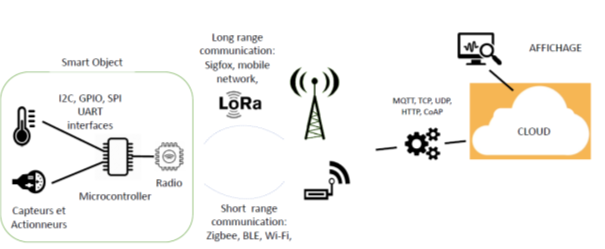

Dans le contexte de l’IoT rappelé ci-dessus, on se place en aval au niveau CLOUD, espace dans lequel se trouvent stockées la donnée mais également, une métadonnée voire une ontologie, pour la sémantique. Rappelons que cette architecture globale permet à des objets connectés et notamment des capteurs d’interagir de façon autonome. Cette interaction peut se faire au travers de commandes et d’échanges d’information. Il s’agit bien de récupérer une information sur un système monitoré et d’agir au travers de commandes. La diversité des capteurs et actionneurs conduit à envisager des opérations plus ou moins sophistiquées et notamment liés à l’apprentissage et à l’IA.

Les familles de traitement de la donnée existent allant de la visualisation à l’apprentissage.

On peut considérer que le traitement le plus simple est la visualisation de la donnée sous forme de graphes ou d’indicateurs. Cette donnée est ensuite utilisée pour construire soit un système d’alarme, de contrôle et de supervision, de régulation voire de diagnostic. Enfin la prévision du comportement du système est la phase la plus sophistiquée.

### Description du problème

#### Description du problème

Revenons à l’équipement de la boite noire équipant un patient chez un médecin : si le capteur de température enregistre une valeur 37,2 la métadonnée donne une sens à cette valeur, il s’agit d’une température dans une unité de mesure, le degré Celsius. Si cet enregistrement est continu, on peut espérer avoir la séquence des valeurs de températures enregistrées à chaque pas de temps.

![204123046](https://t3.ftcdn.net/jpg/02/04/12/30/240_F_204123046_xzA9r1OSMhbZrdkXflaaGzvhmS9QvD7i.jpg)

Si une sortie directe existe, on peut alors visualiser en direct la température suivie et programmer une alarme par exemple, la visualiser et plus encore.

Dans une architecture IoT, on espère avoir accès à la température suivie en direct de la même façon comme si le ou les réseaux n’existaient pas.

De nombreux exemples peuvent être cités : on peut aisément se positionner dans un contexte de bâtiment intelligent (smart) connecté avec un grand nombre de capteurs dédiés à la surveillance et au contrôle du bâtiment d’un point de vue thermique.

Bien que classique la surveillance et le suivi de la température dans une pièce sera notre exemple type. Dans ce cas, donnons quelques éléments fondamentaux :

-          Le suivi de la température dans une pièce impose de disposer de la description du dispositif : un ensemble de capteurs- émetteurs connectés via un système IoT (Réseau i*ntelligent* contextuel et sémantique) - une réception avec stockage de la donnée reçue,

-          Le *système* est le système physique de la pièce chauffée (avec une source de chaleur) ou de la pièce climatisée (l’absorption de la chaleur dans le cas de pièce réfrigérée) dont on veut suivre le comportement thermique fourni par la température *indoor*. Ce système doit être borné : la pièce dans le bâtiment est limitée par ses murs caractérisés par leurs propriétés physiques ; elle contient le dispositif de chauffage et est associée à des activités ou des usages de la pièce. Si on s’intéresse au bâtiment, le système est composé alors de plusieurs pièces qui constituent le système global.

***Définitions :***

o   On désignera par **s*ystème***, l’objet ou l’environnement suivi par un dispositif de capteurs (objets connectés), quelques exemples : une pièce chauffée dans un bâtiment, un patient équipé pour son suivi médical, un réseau de distribution d’énergie pour suivre sa charge.

o   On appel **la *grandeur mesurée*** :la composante physique pouvant être mesurée par un capteur et transmise: comme la température, l’humidité, la pression, la radiation solaire…

Dans l’idéal, on souhaiterait disposer de la vraie valeur de la grandeur par exemple la température, qui est mesurée par le dispositif mis en œuvre pour le suivi d’un système (une pièce chauffée, un monitoring sur un patient,). On parle alors de la meilleure estimation de la grandeur physique mesurée. Attention, il faut bien distinguer la valeur mesurée que l’on souhaite récupérer (*data* via la chaine de l’IoT) et la valeur réelle de la température. La valeur réelle de la grandeur mesurée n’est pas connue exactement mais approchée par la mesure qui en est faite.

Il faut disposer d’un moyen de qualifier la donnée :

* soit disposer de techniques pour définir si la donnée reçue est bien représentative de la donnée mesurée et enregistrée.
* soit déterminer si la valeur mesurée est-elle fiable au sens où elle représente la valeur de la grandeur physique (notion d’outlier ou de dérive) et si cette donnée est fractionnée est-elle exploitable (donnée manquante).

Avant de revenir sur la donnée reçue et sa qualification avant toute utilisation dite’ i*ntelligente*’, il est nécessaire de revenir sur certains composants autour du système de la chaine entre l’acquisition, la réception et le stockage.

## Données stockées de grandeurs mesurables et analyse de données (invisible des apprenants)

### Données stockées et grandeurs mesurables - Définitions

#### Données et grandeurs mesurables

# **Données et grandeurs mesurables**

A ce stade, les données ont été émises, transmises et réceptionnées et on se place au niveau du stockage (cloud ou en local). Il s’agit bien de données qui doivent être représentatives – au sens de la valeur enregistrée par le capteur au niveau du système monitoré avant sa transmission via le réseau.

La donnée est la valeur d’une grandeur mesurable comme la température enregistrée et transmise à partir du capteur positionné dans la pièce.

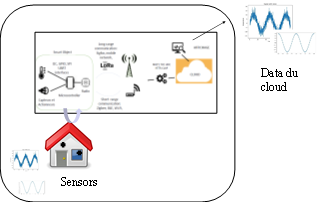

Les données collectées sont l’essence même des IoT.  Ces dernières permettent d’observer un système :  soit pour le visualiser, faire de l’exploitation et du diagnostic, voir prévoir le système au travers de capteurs donc de données.

#### Vidéo : Ce qui est attendu de la chaine IoT

# **Vidéo : Ce qui est attendu de la chaine IoT**

#### IA et science des données

# **IA et science des données**

L’analyse de données et la statistique au cœur des méthodes et outils pour l’exploration avancée des *data* et notamment avec les outils des IA.

L’Analyse de donnée et les Statistiques vont permettre de transformer les données en **information** par un premier niveau d’analyse, puis l’exploitation et l’interprétation vont permettre d’extraire de la connaissance sur le système monitoré : on parle alors *d’intelligence de la donnée.*

 Dans une phase initiale il est nécessaire de poser certaines questions : quel est l’objectif de l’acquisition de ces données, comment est définie la mise en place opérationnelle de l’acquisition en s’assurant que la mesure qui est faite est fiable et reproductible.

Il existe certains principes de précaution, qui assurent que :

* L’abondance des données n’est pas une garantie de qualité,
* L’acquisition de données est une étape nécessaire et délicate pour garantir la pertinence vis-à-vis de l’objectif poursuivi ( *garbage in, garbage  out*),
* Enfin, lors de la récupération des données *(sur le cloud , sur le data logger*), plus de 50% du temps est nécessaire à la préparation de de la donnée avant toute exploitation *décisionnelle.*

o   *Quels domaines sont sous-jacents à l’IA :*

* La **statistique** est associée i) au recueil, ii) au traitement iii) à l’interprétation d’un ensemble de données et iv)  à la visualisation.
* Les **probabilités** sont associées à l’étude mathématique de phénomènes dépendant du hasard et de l’incertitude.
* L’**analyse de données (AD)** dont l’analyse de données exploratoire regroupe les méthodes permettant de traiter les données multidimensionnelles et notamment recherche les liens entre données. Il existe un lien fort entre statistique et probabilités. Ces deux domaines des mathématiques appliquées sont à la base des techniques de l’Apprentissage Automatique et du *Machine Learning* et constitue une partie des fondements de l’intelligence artificielle dite IA numérique (qui s’oppose à l’IA sémantique ou explicative). Les outils mathématiques et des statistiques sous-jacents sont un des domaines incontournables de la **Science des données,** regroupant également l’informatique et la théorie de l’information. Cette discipline a un rôle prépondérant dans le contexte de l’IoT et de la *data*.

La **donnée** est définie par des entités qui contiennent de l’**information** : il s’agit par exemple, d’une donnée de mesure, d’une notation, d’une caractéristique, d’un jugement…Les données sont de nature différente :

* Données quantitatives (mesure de température, radiation, pression…...) : donnée dite continu
* Données qualitatives (catégorie, valeur ordinale, jugement...): donnée textuelle

La Donnée est associée à une **variable** qui peut être de nature qualitative (nominale *sans ordre* ou ordinale) ou de nature quantitative soit de type discontinue (donnée de comptage) ou continue (mesure physique).

La **Science des données** s’intéresse à des données de toutes origines, de tous types et de structures et de tailles différentes. Dans le contexte de l’IoT et de cette section on se limitera aux données numériques associées à des grandeurs mesurables par un capteur. Dans ce cas, la donnée est fournie sous la forme d’un fichier stocké ou reconstruit dans la base de données; chaque ligne correspond à un enregistrement et en colonne, les attributs ou propriétés de chaque enregistrement.

Par une transformation adéquate, on considéra qu’une ligne du tableau généré est associée à un individu, soit une observation du phénomène perçue au travers de grandeurs physiques notamment. La représentation des données est une matrice de dimension *n*, nombre d’individus. Un individu appartient alors à un échantillon de dimension *n*. Pour une série de mesure à chaque pas temporel, un individu *i* est associé à une date et une heure de mesure. En colonne, chaque caractéristique est une variable contenant la valeur enregistrée pour chaque individu *i*. Cette valeur correspond alors à la grandeur mesurée.

### Eléments de statistique et d’analyse de données pour les données de l’IoT

#### Définitions des grandeurs mesurées

# **Définitions et quelques éléments de manipulation des grandeurs mesurées :**

o   En Statistique : on appelle *X* la variable associée à la température et qui prend ses valeurs sur l’espace des réels pour chaque pas de temps (pas d’enregistrement du capteur).

o   Ainsi, on associe un ensemble de valeurs *X**i*entre t0 et tn , les valeurs prises par cette variable durant la période de t0 et tn .

o   Si on dispose de plusieurs valeurs de grandeurs mesurées *X**j**, l’ensemble* de valeurs *X**ij* *entre* t0 et tn , sont les valeurs prises par ces variables durant la période de t0 et tn pour un individu *i*.

####  Vidéo : Analyse de données pour explorer les données

# **Vidéo : Analyse de données pour explorer les données**

### Analyse statistique univariée sur donnée quantitative

#### L'analyse univariée

# **L'analyse univariée**

L’analyse univariée permet :

–      D’étudier une variable isolée,

–      De préparer une phase « multidimensionnelle » : soit travailler sur une donnée multidimensionnelle (dans un espace *E**p*),

–      Acquérir une connaissance intrinsèque des données,

–      Prévenir les effets néfastes dus à la structure des données (distribution non symétriques, outliers, « pauvreté » et déséquilibre du nombre de modalités et de la fréquence des valeurs,…) .

L’analyse univariée permet de faire l’étude de la structure des données.

 L’objectif de cette étude est de :

§  Découvrir la forme et les caractéristiques du phénomène

§  Comparer globalement le phénomène à un autre

§  Détecter d’éventuelles anomalies (valeurs aberrantes)

Elle se fait soit par des représentations graphiques, soit la construction d’indicateurs résumant l’ensemble des valeurs.

#### Les outils

# **Les outils**

* **L’histogramme**

*L’histogramme* permet d’établir la répartition de la variable par rapport aux individus en fonction de ces modalités.  
Sa construction permet :

+ D’obtenir la distribution de la variable/individu
+ La Construction de rectangles adjacents dont les **surfaces** représentent les effectifs de chaque classe de la distribution.

Un exemple, sur les données suivantes :

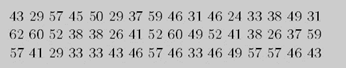

*Données : Tableau des âges de 48 salariés*

Déterminer l’occurrence pour chaque classe : soit les effectifs par intervalles **[e1,e2[**

Calcul de l’histogramme pour 5 classes, 10 classes , 15 et 20 classes :

           Effectifs :  5 classes [ 8. 10. 13.  7. 11.]

           Effectifs :  10 classes [ 3.  5.  4.  6.  3. 10.  4.  3.  6.  5.]

           Effectifs :  15 classes [3. 3. 2. 4. 0. 6. 3. 3. 7. 3. 1. 3. 0. 8. 3.]

           Effectifs :  20 classes [1. 2. 3. 2. 4. 0. 2. 4. 3. 0. 3. 7. 0. 4. 3. 0. 0. 6. 4. 1.]

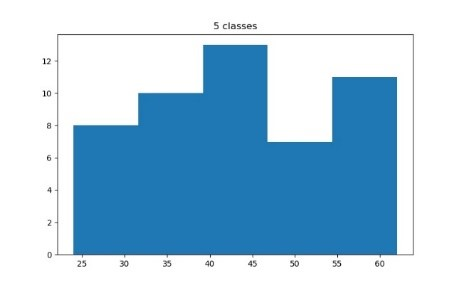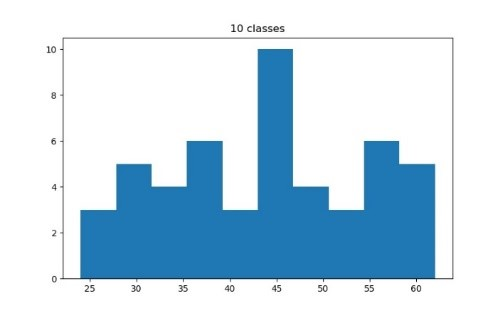

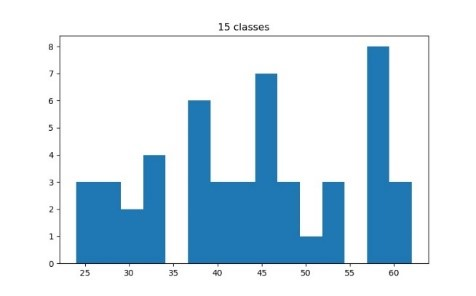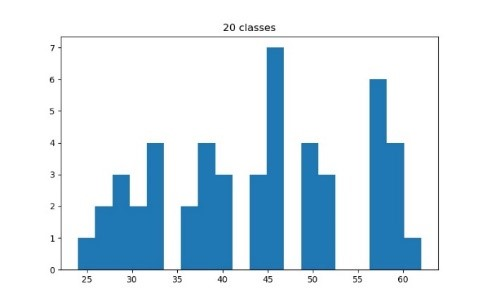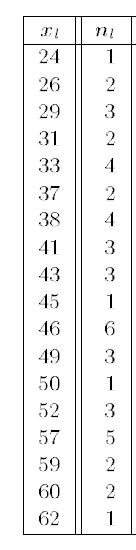

Nécessite le choix du nombre de classe pour un histogramme

Le *diagramme circulaire* permet également de montrer l’importance relative des classes d’une distribution, avec la distribution de la variable/individu et le calcul des angles de chaque secteur, dont la surface représente l’effectif de chaque classe.

* Exploration statistique des données : **indicateurs de variables quantitatives :**  

  C’est l’étude des fluctuations d’une variable quantitative, pour répondre à 3 questions :

   1.Quel est le niveau (valeur de la variable) des individus selon un caractère ?

   2. Existent-ils de grandes différences entre les individus ?

   3. Peut-on se demander si la répartition des valeurs observées correspond à un modèle particulier qui décrive la forme générale des valeurs obtenues ?

   Il existe des indicateurs de Tendance et de dispersion.
* **Indicateurs de tendance centrale** ***:*** 

   La **Moyenne** arithmétique :

  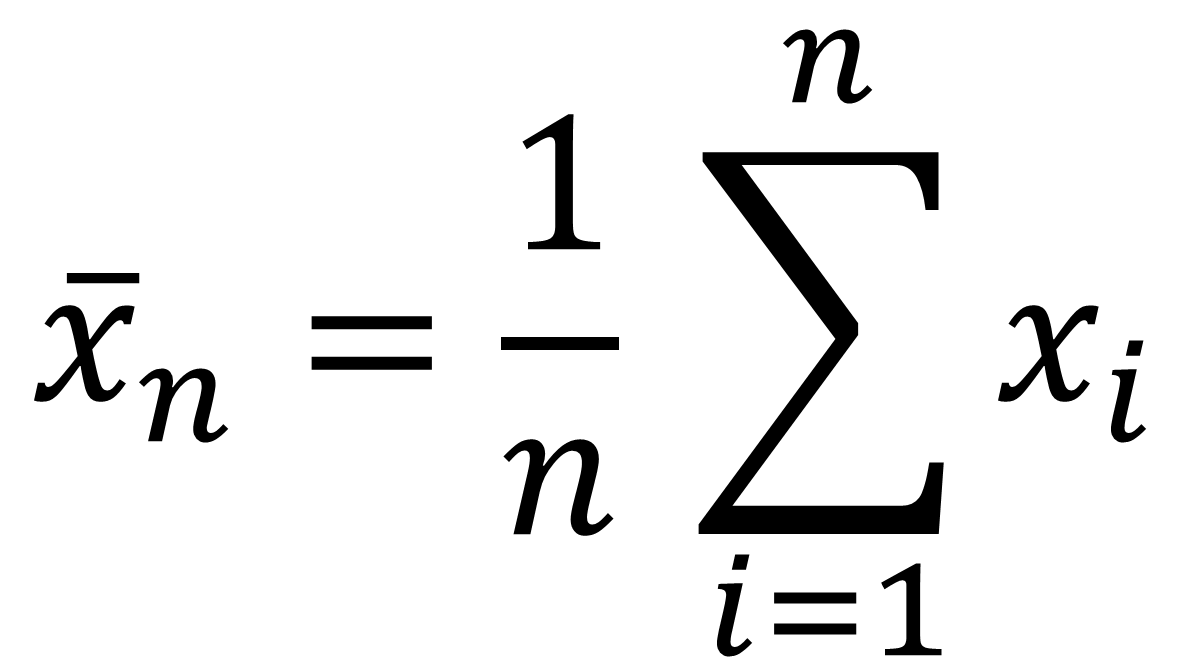

**La Médiane** : valeur qui partage en 2 l’échantillon (c’est la valeur qui correspondant à une fréquence de 50 %) :   
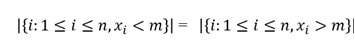  
Le mode est la valeur de la variable présentant la plus grande fréquence d’apparition.Les Quantiles à p% > ou < : si  la fréquence f% est relative aux individus de valeurs > ou < au quantile q(p)

* **Indicateurs de dispersion :**

 L’**Étendue** est l’écart entre la valeur maximale et valeur minimale.  
La **variance** mesure de la concentration (ou de la dispersion) des valeurs autour de la valeur moyenne de la variable x ;  
L’**écart-type** (std)  est égal à la racine carrée de la variance.

–         Ordre de grandeur de la variable/individu => **Valeur centrale**

–         Fluctuation autour de cet ordre de grandeur => **Dispersion**

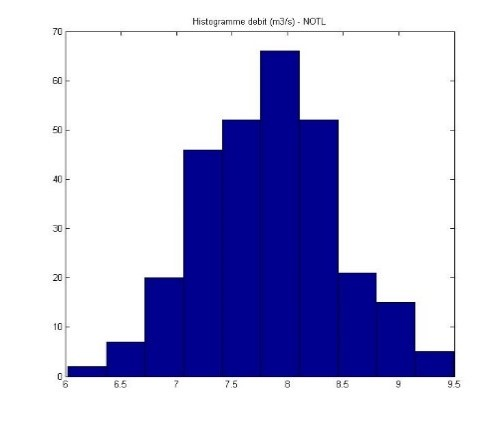

 La **courbe cumulée**, elle permet de :

–         Connaître combien d’unités comporte la distribution au-dessous d’une certaine valeur (cumulée croissante)

–         Connaître combien d’unités comporte la distribution à partir d’une certaine valeur (cumulée décroissante)

–         Interpolation (distribution de la var. aléatoire associée)

Sa construction permet l’obtention de la distribution de la variable/individu. L’effectif cumulé croissant de la *k**ème* classe  est la somme des effectifs de la première à la *k**èm*e classe. L’effectif cumulé décroissant de la *k**ème* classe est la  somme des effectifs de la dernière à la *k**ème*classe incluse.

 Pour l’effectif cumulé croissant, il est nécessaire de :

–         calculer le nombre d’occurrences de chaque valeur (ni)

–         calculer la fréquence relative pour chaque classe k:  ex pour la premier valeur : 1/48 soit 2.08 %

—     Calcul de la fréquence cumulée de chaque classe, k :  ex. pour la 2eme classe : 2.08 + 4.17 soit 6.25 % pour les données suivantes.

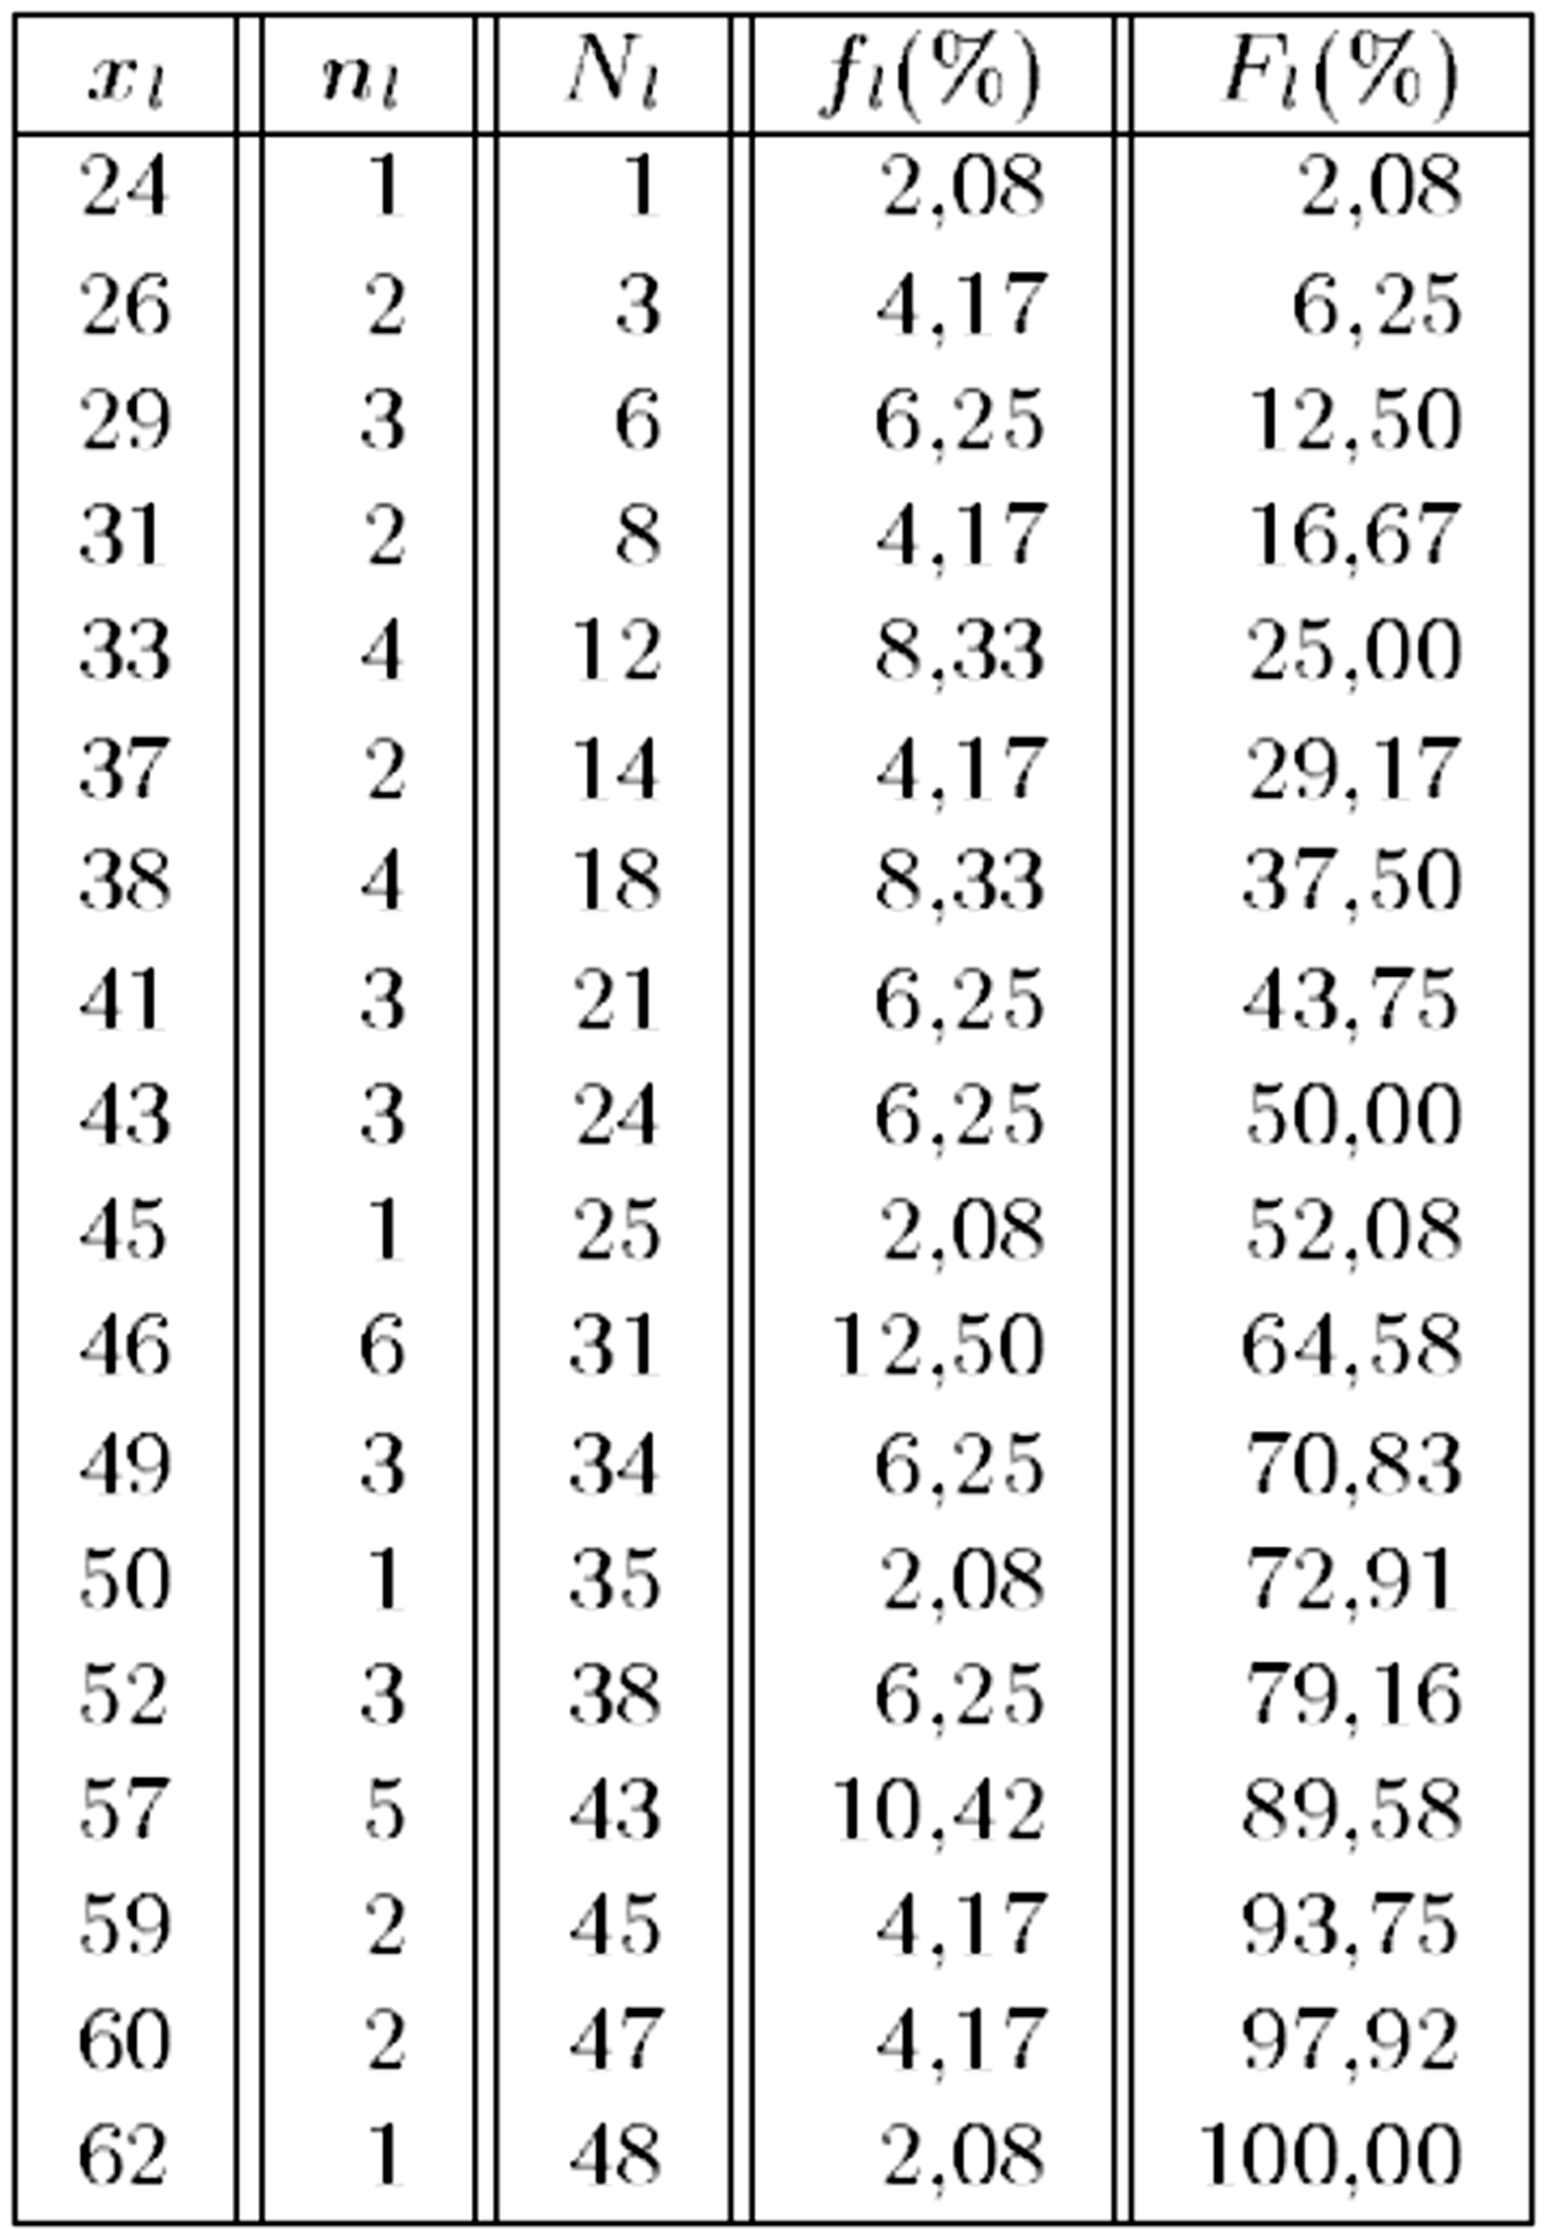  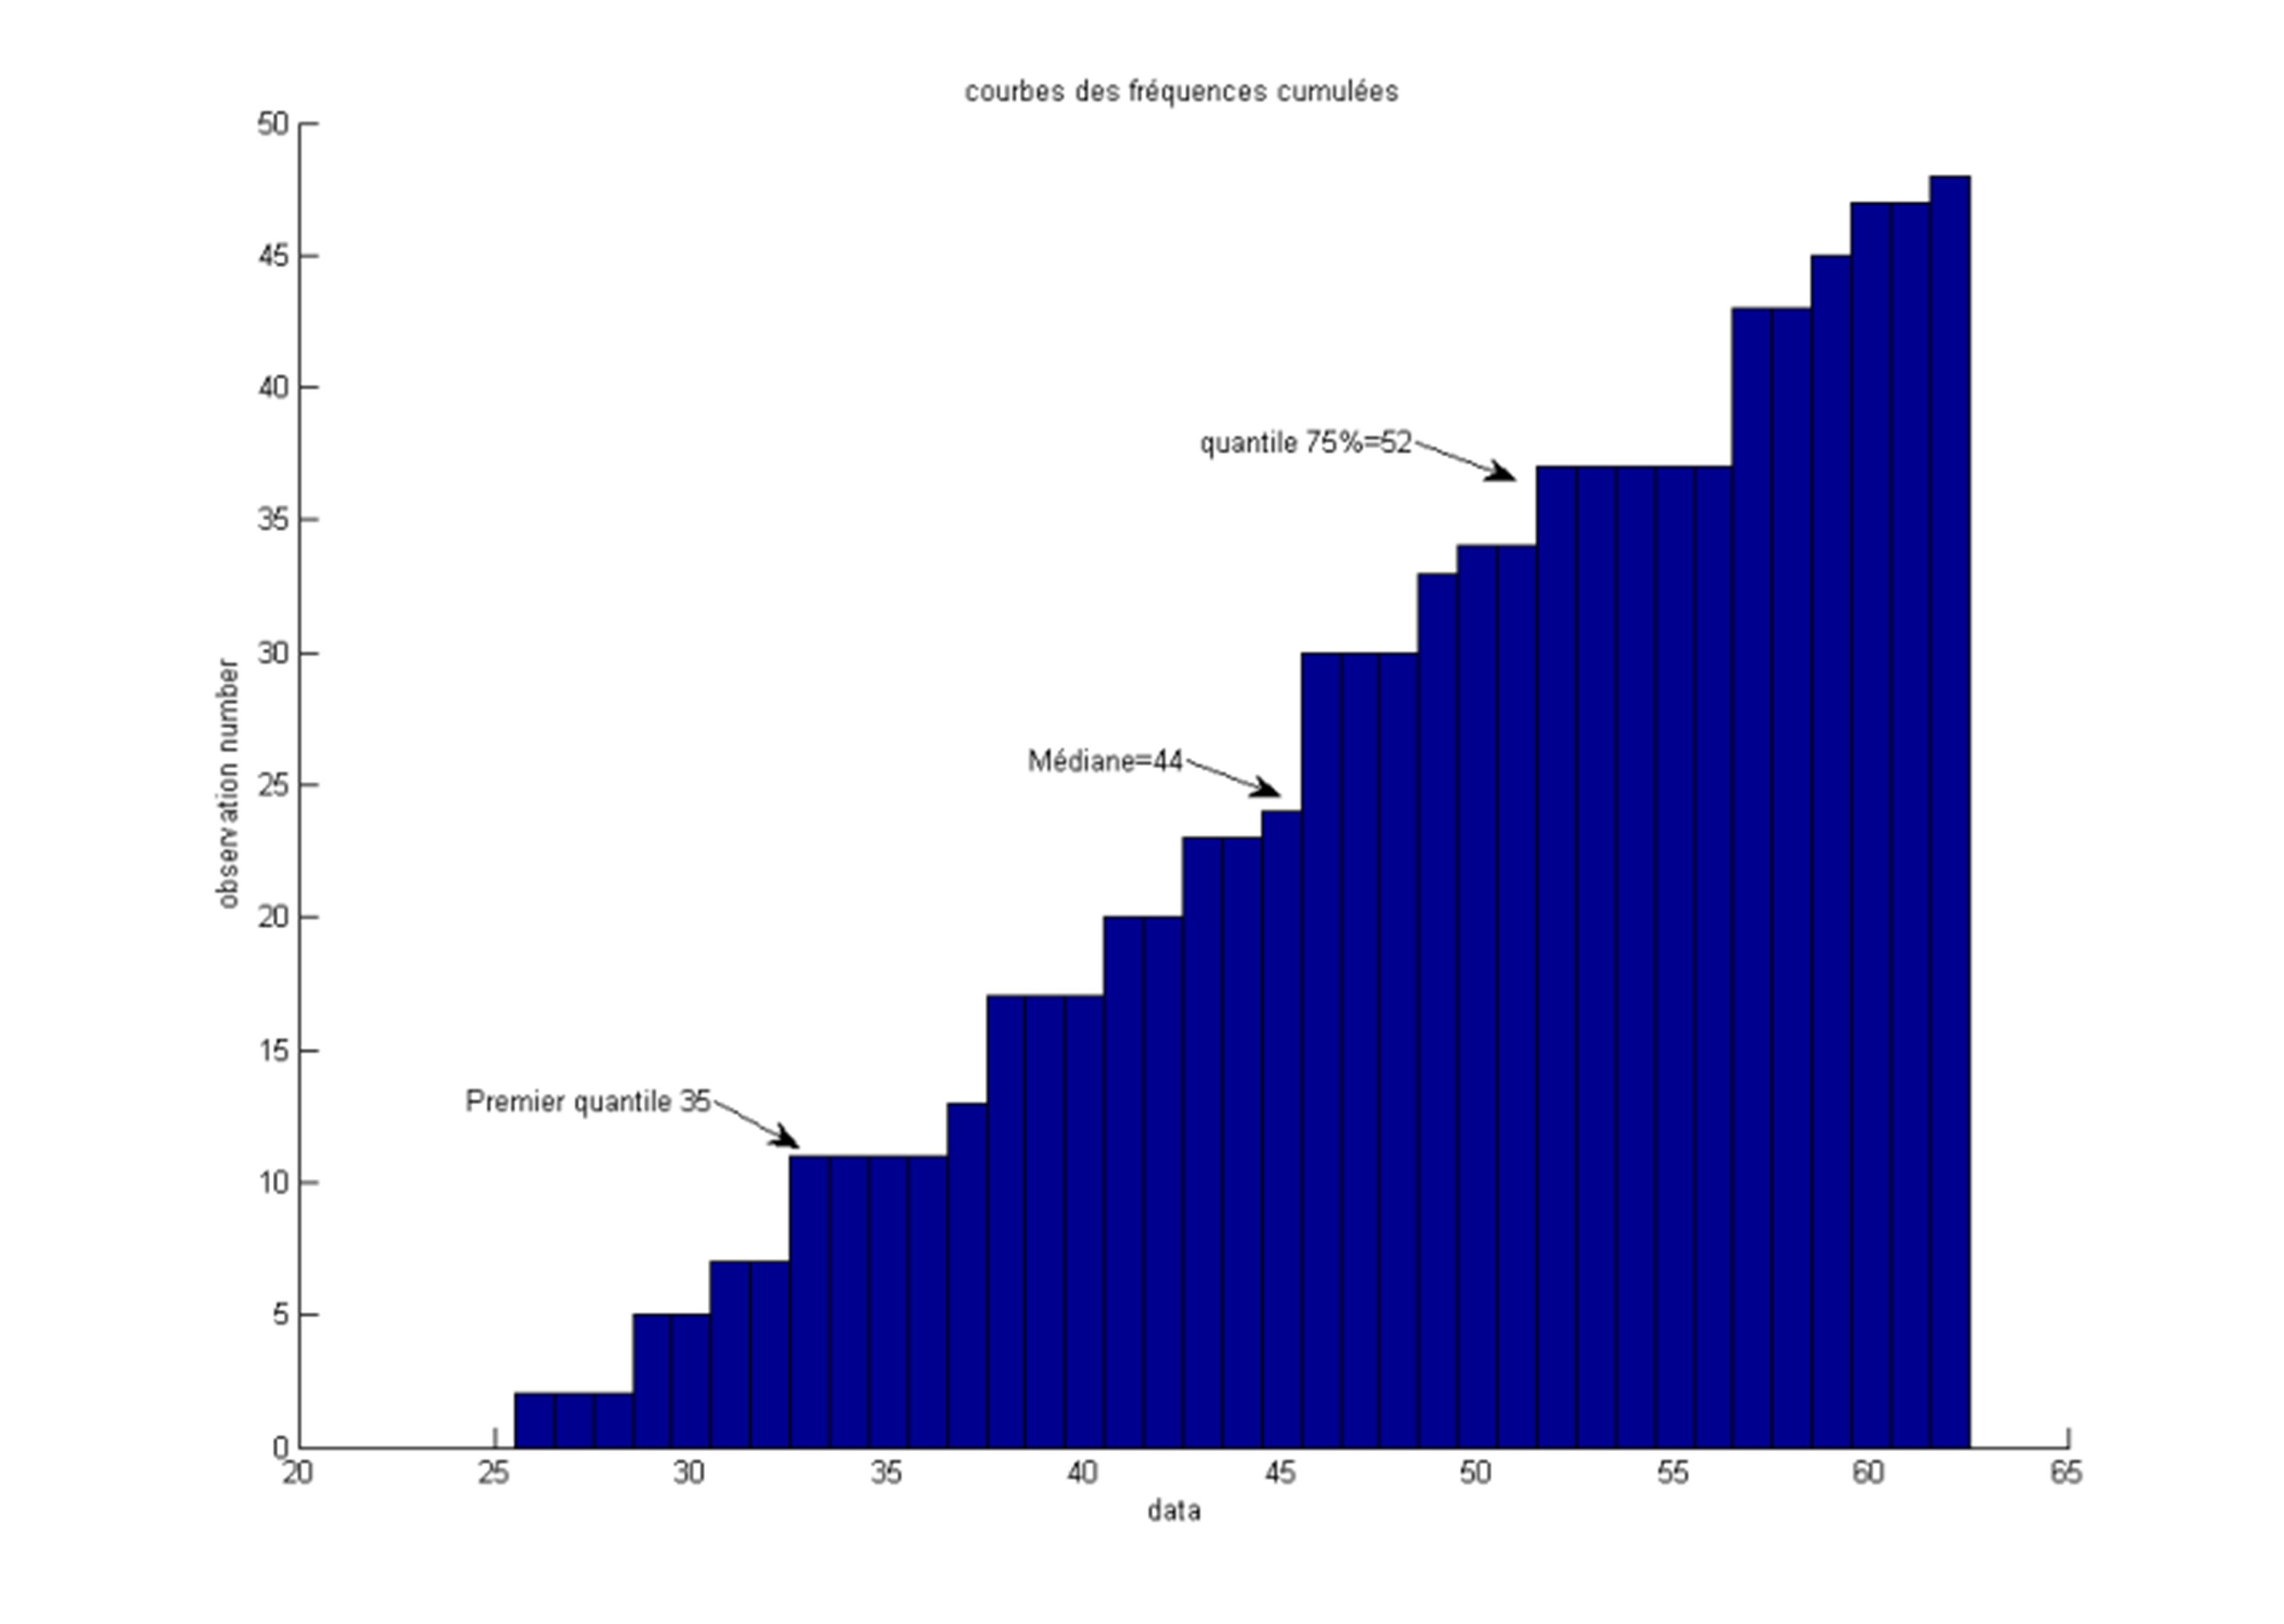

* **Le quantile :**

Le *quantile* *q(p)* est la valeur *x**p*que prend la variable *x* tel qu’une proportion *p* d’observations soit plus petite que *q(p).* Cette valeur *x**p*, dit *quantile* *q(p)* d’ordre *p* est la valeur qui partage la série statistique ordonnée en deux sous-ensembles, contenant un nombre d’observations à peu près égal à *n**´**p* et *n – n**´**p* = *n**´**(1 - p), soit respectivement une proportion a peu près égale à p et (1-p). L*e **q(50%) quantile** est la ***médiane*** . Les quantiles q(25%) et q(75%) sont le premier et le troisième quartile (*quantile des multiples du quart )* de rang (n+3)/4 et (3n+1)/4 (le second quartile est la médiane). L’écart interquartile contient  50%  des observations .

**Exemple de calcul de quantile x****1/2****:** Une série de surfaces SAU en ha: pour les 6 classes ci-dessus sont données la fréquence en pourcentage. La moyenne: **manque la formule**

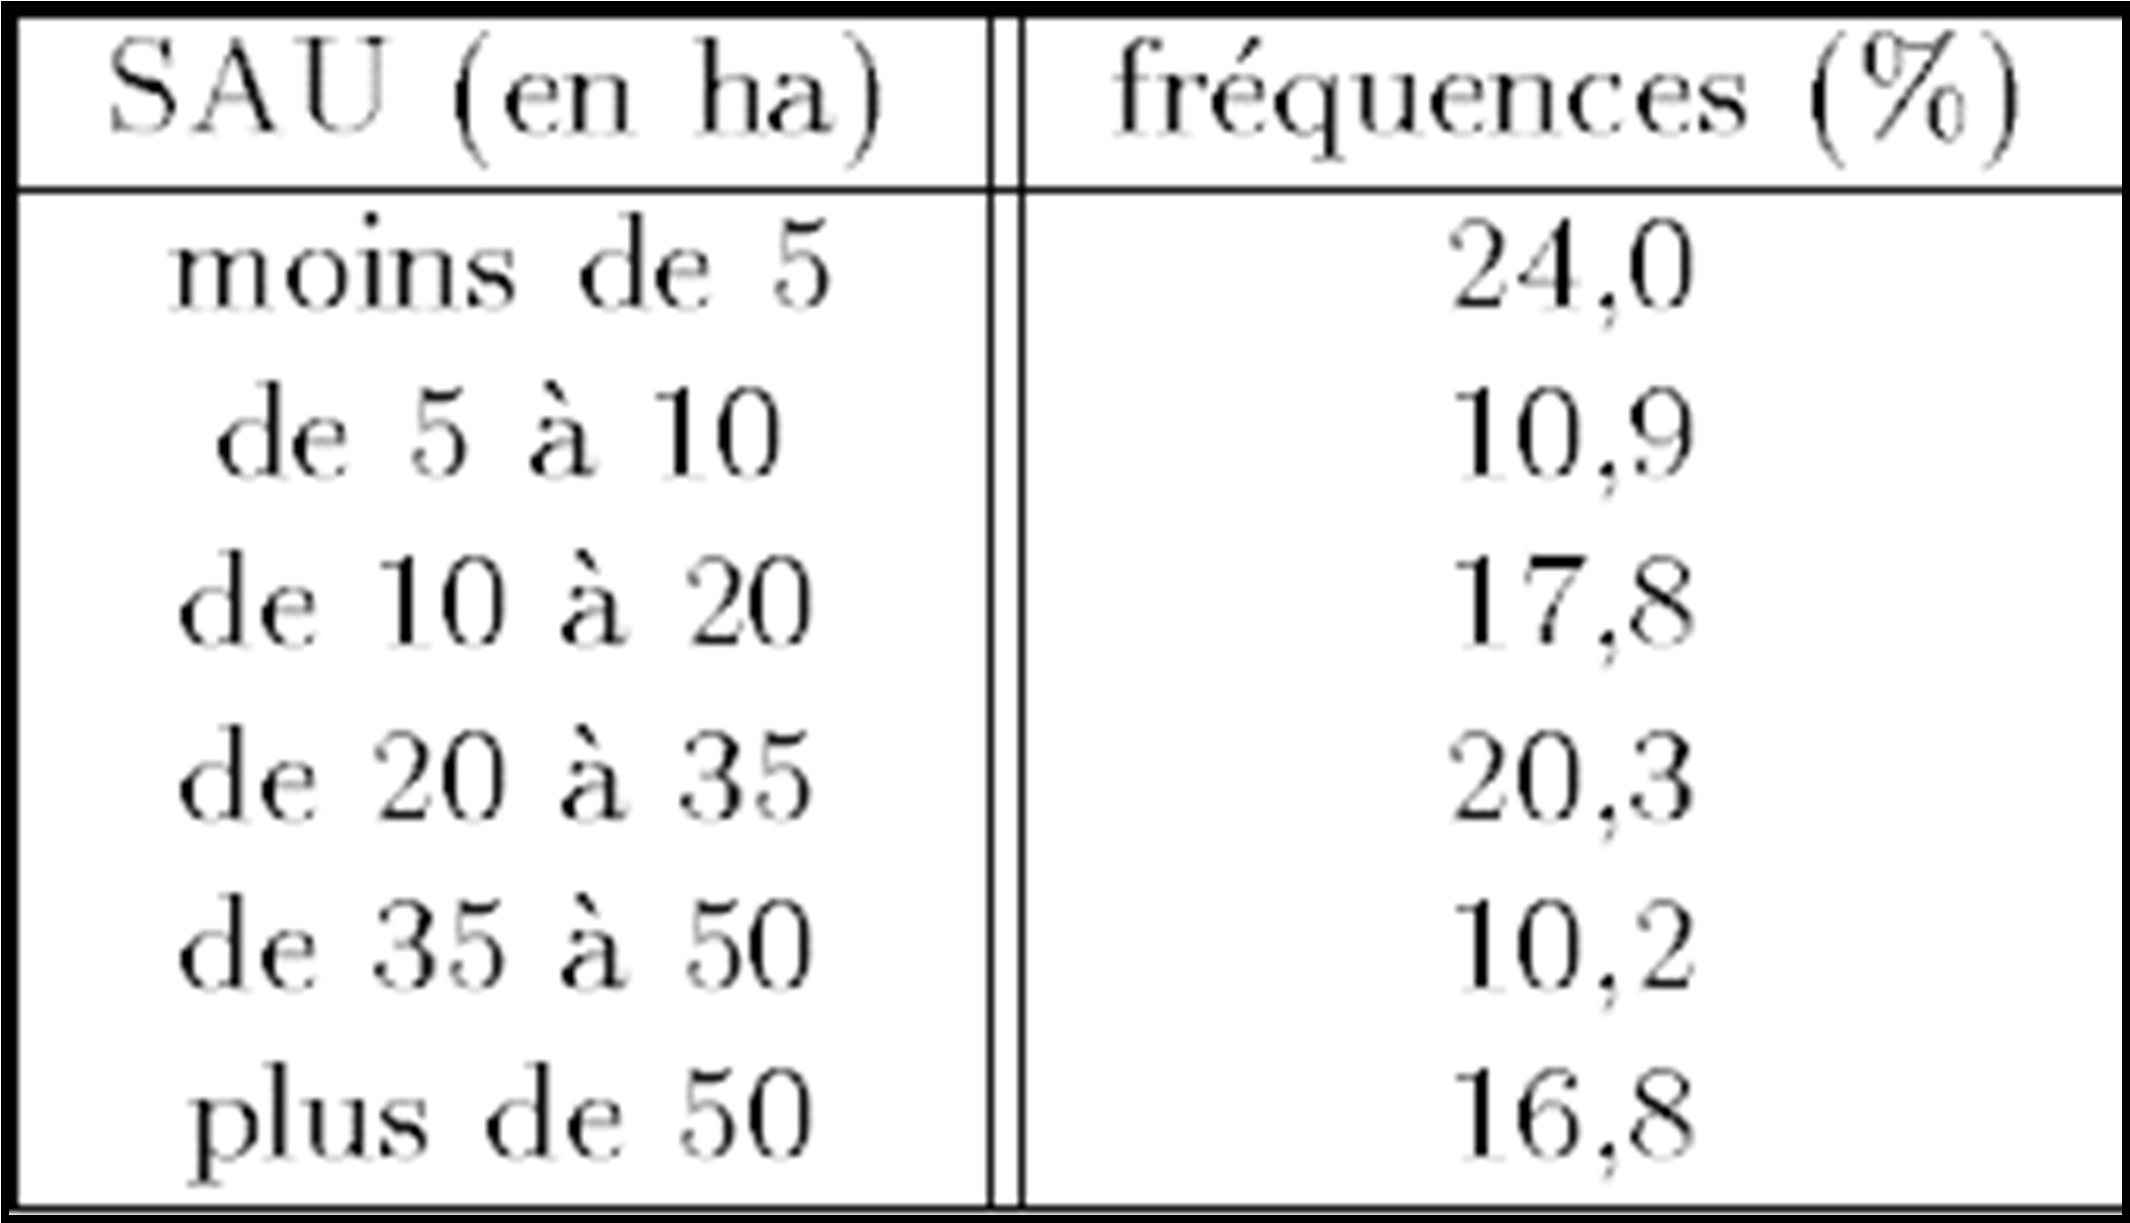    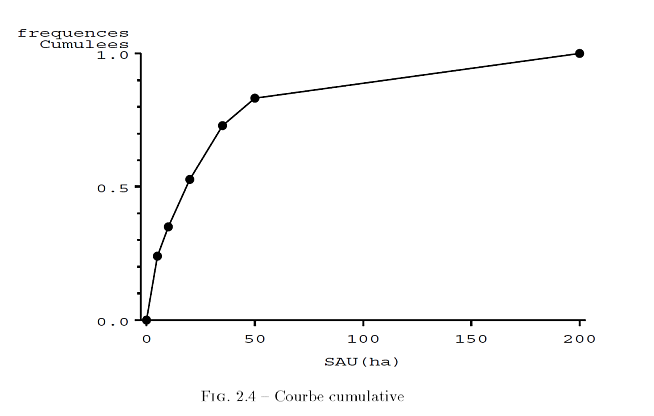

**La médiane** est dans la classe 10 -20 (34,9% et  52,7%) et est obtenue par interpolation linéaire.

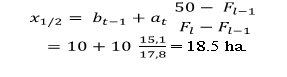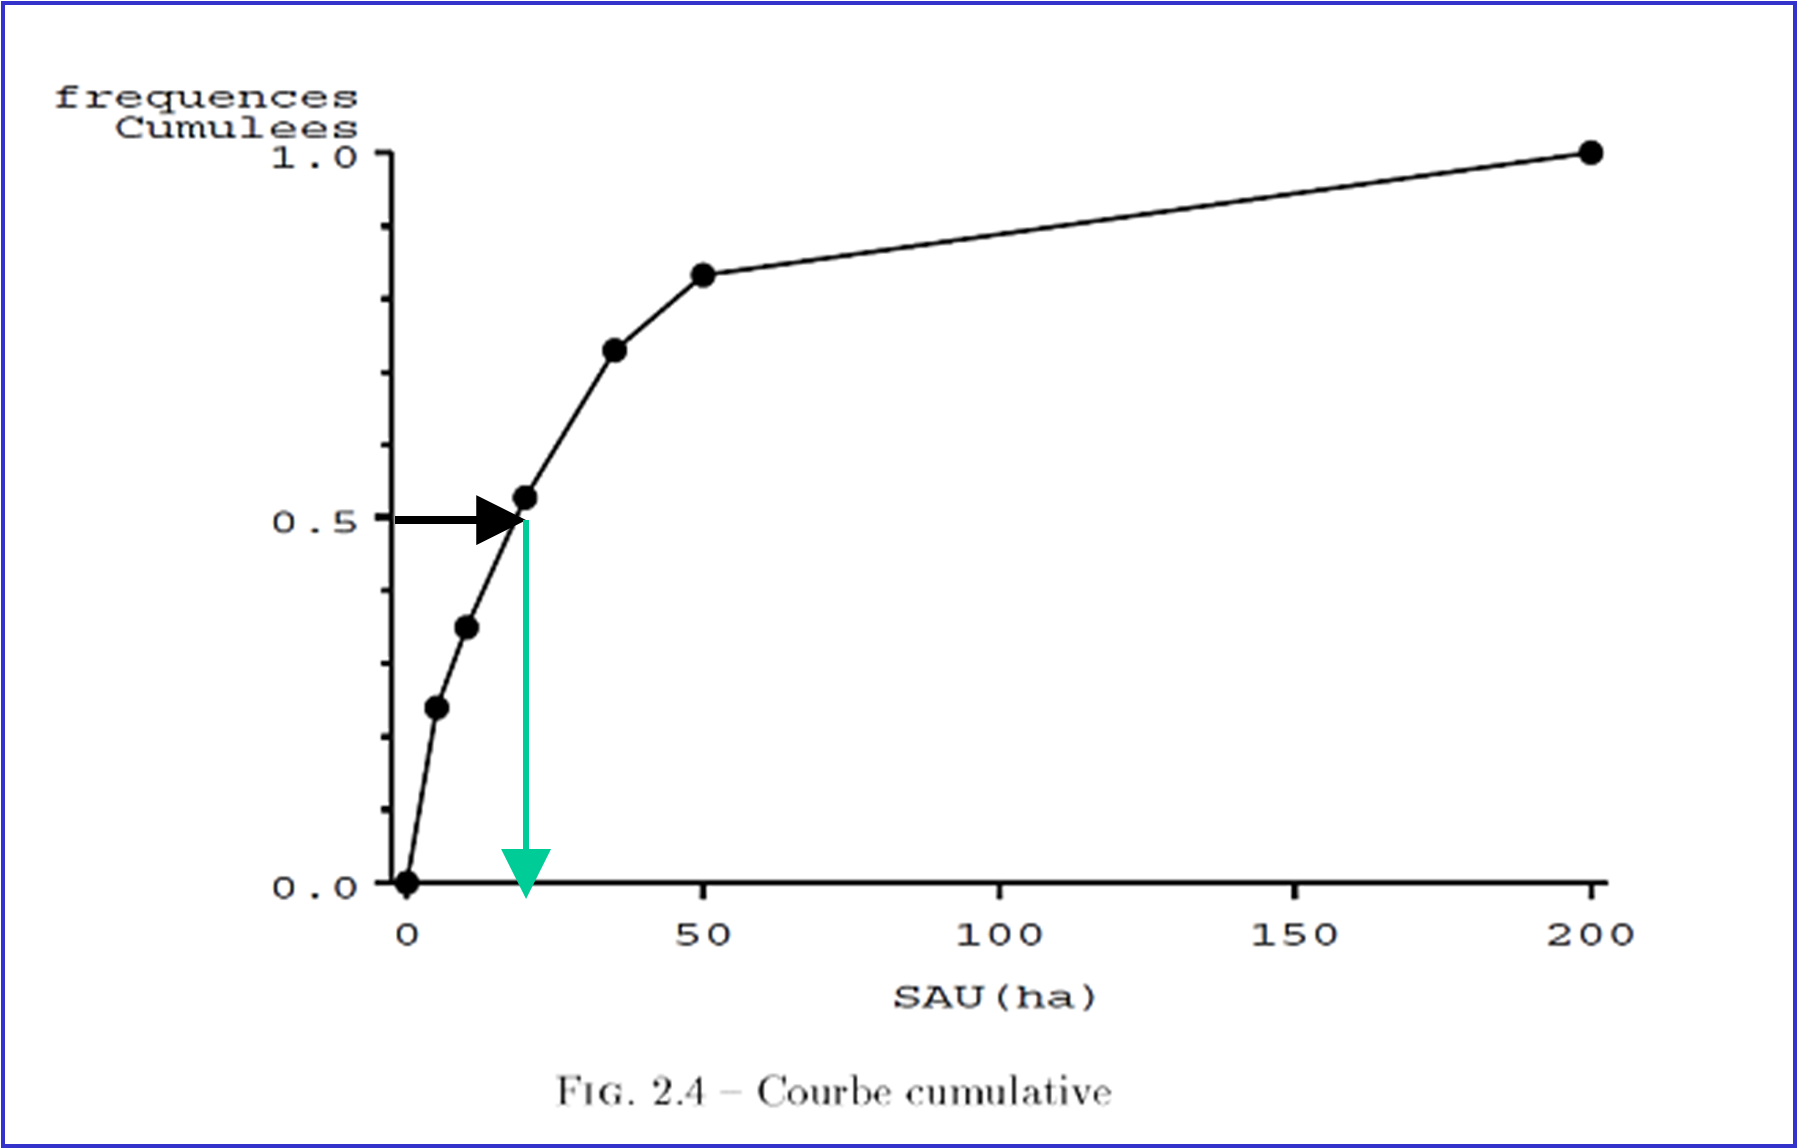

* Indicateur de tendance et de dispersion : **la boite à moustache**

La boîte à moustaches est une méthode de *présentation graphique* des indicateurs de tendance et de dispersion des données. Les informations fournies sont:

- la plus petite observation (échantillon minimum), le quartile 1 (quantile *q(25%)),* la médiane(50%), le quartile 3 (75%), la plus grande observation.

- les valeurs atypiques éventuelles.

-la lecture se fait de bas en haut, du quartile inférieur au quartile supérieur. Les moustaches connectent la boîte aux plus petites et aux plus grandes valeurs qui ne sont pas des valeurs atypiques éventuelles (point en dehors) .

 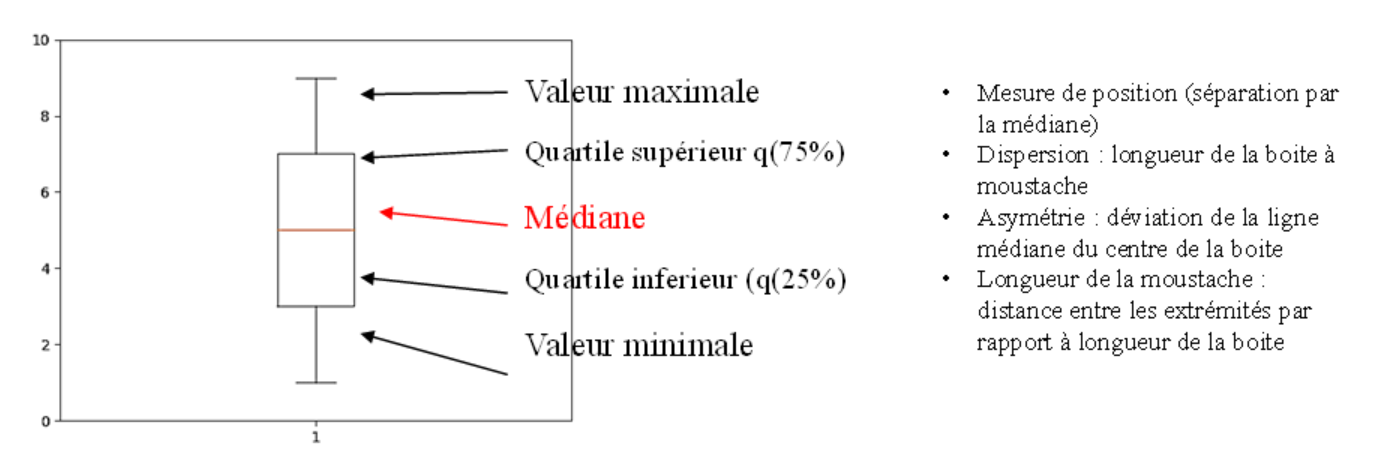

* Exploration des propriétés des échantillons issus de population :

Une **population** est un ensemble dont les éléments sont des individus.  
Un **échantillon** est une suite finie d’individus issus d’une population. Chaque individu constitutif est décrit par des variables (ou caractères ou attributs,)  
Une **variable** est une fonction de la population dans un ensemble de valeurs discrètes ou continues.

 On appelle X la variable numérique associée à une grandeur mesurable (ex.la température) et qui prend ses valeurs sur l’espace des réels pour chaque pas de temps (pas d’enregistrement du capteur). La moyenne/espérance : sur un échantillon de dimension *n*, on a mesuré la variable quantitative X , la moyenne de cet échantillon est la moyenne arithmétique sur cet échantillon.

 La moyenne est l'***espérance*** de la variable **manque la formule**    qui a *i* fait correspondre *x**i* sous la loi de probabilité uniforme *P* sur l’échantillon sur lequel on a mesuré la variable quantitative *X* ; on note **manque la formule**

 Les propriétés des échantillons issus de populations sont la fonction de répartition F(x) et la fonction de densité f(x).

–         Etant donné un échantillon *{1,…n}* et une variable quantitative *X* avec *X(i) = x**i* , **la fonction de répartition** *(f.d.r)* associée à *X* est une fonction *F**n*dont la valeur en *y* notée *F**n**(y),* est le poids des points de l’échantillon pour lesquels la variable  *X* est inférieure ou égal à *y* .Elle est définie de   **manque la formule**  .

-      Elle correspond également à la probabilité **manque la formule**

-        Elle est construite à partir de la courbe de fréquences cumulées.

–         De même, on peut définir la **fonction de densité notée** ***f*** **de la variable** ***X*** **,**lorsque qu’elle existe et est bornée, et peut être construire et estimée à partir de l’histogramme. Elle permet de trouver la probabilité qu’une valeur *x* se trouve entre deux bornes *a* et *b. Elle est la fonction dérivée de la fonction de répartition F(x) tel que* ***manque la formule***

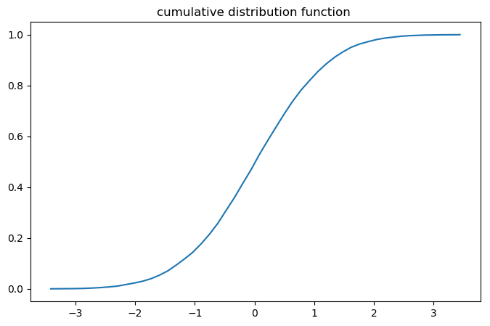        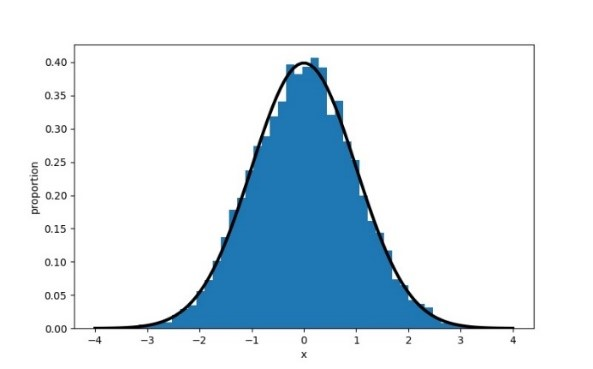

Cas d’un échantillon aléatoire suivant une loi normale p(x)\* pour x dans l’intervalle (-4,4) avec    
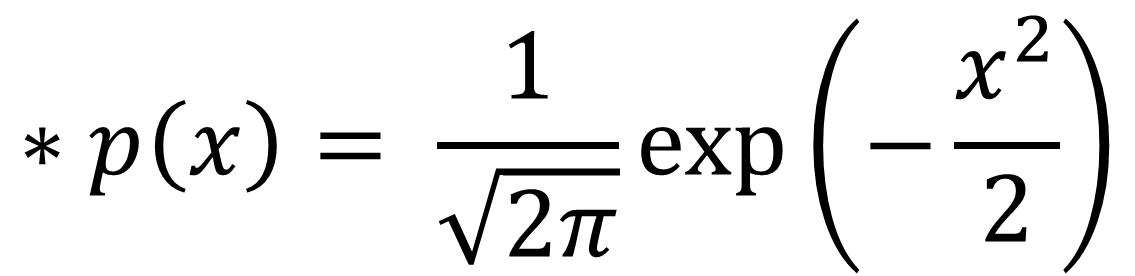

A gauche : courbe cumulée  ® estimation de la fonction de répartition  
À droite : la fonction de densité superposée à l’histogramme de répartition de la variable X

* Deux propriétés des échantillons : la  **variance et l’écart -type** 

  ***Variance et Ecart-type :***

  Etant donné un échantillon *{1,…n}* et une variable quantitative *X* avec *X(i) = x**i* ,de moyenne ***manque la formule*** , la **variance** empirique  est l’écart quadratique moyen des points de l’échantillon à la moyenne :

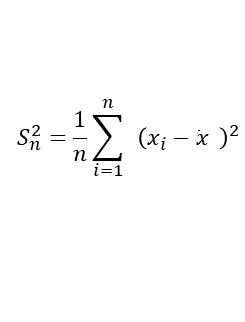

On appelle ***l’écart-type*** *ou la* ***déviation standard*** ***manque la formule***

**L’Analyse statistique** permet d’aider à comprendre ou à conduire des phénomènes réels. C’est un ensemble d’outils qui s’appliquent à des ensembles d’informations numériques qui représentent le phénomène étudié lorsque l’étude directe ou exhaustive du phénomène est non possible - ensemble de données décrivant de façon incomplètes un phénomène.

A ce stade de la session, un quizz et un TP de manipulation permettre de mettre la mise en œuvre de ces outils sur des données de température.

### Quiz 5.3

**Quiz : Quiz 5.3**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1-En statistique, probabilité ou analyse de données : Que manipule - t- on ?** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['De la donnée', 'De l’information', 'Les deux\xa0: information et donnée'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'Les deux\xa0: information et donnée'}, ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



## Validation de la donnée : Données manquantes - données fiables - données outliers: (invisible des apprenants)

### Notion de validité de la donnée reçue

#### Notion de validité de la donnée reçue

# **Notion de validité de la donnée reçue**

On se positionne à cette étape dans le contexte de suivi par Objets connectés d’un système. Les caractéristiques sont que :  
o    Les Données sont issues de capteurs variés et nombreux  
o    Les Capteurs sont localisés (position, géolocalisé)   
o    Le Suivi d’un dispositif, d’un procédé ou d’une installation, un bâtiment, appelé système est fait  
o    Les données sont issues des sensors et qu’une architecture IoT est disponible permettant d’enregistrer dans une BDD ou un cloud les data collectées et transmises par le réseau.  
  
La question est : les données sont-elles de qualité suffisante pour toute IA ou méthodes d’intelligibilité de la donnée. Soit encore les valeurs sont-elles représentatives des valeurs mesurées ?  
  
La problématique de la validation de la donnée est présentée à l’aide de différents exemples : entre l’attendu et le réellement disponible dans le contenu des données existe-il une différence ?   
Les deux vidéos suivantes permettent d’intégrer cette disparité dans la qualité de la donnée reçue ou stockée.

### Vidéo : Validité des données de l'IoT

#### Vidéo : Validité des données de l'IoT

# **Vidéo : Validité des données de l'IoT**

### Qualité de la donnée

#### Qualité de la donnée

# **Qualité de la donnée**

Précisons la notion de qualité sur la donnée. On sait qu’une donnée est manquante car à la date de l’enregistrement de la donnée on aurait dû avoir une valeur, on parle de données incomplètes.   
Pour une donnée on peut aussi se poser la question de la justesse ; non pas versus l’erreur de mesure faite au niveau du capteur (voir première partie de la session) mais bien au niveau de la donnée. La seconde notion est liée à  la question : peut-on faire confiance à la donnée qui est visualisée ? N’est-elle pas une valeur extrême, une anomalie de mesure ou au contraire, elle traduit un vrai changement dans le comportement du système. Il existe des techniques pour traiter ces problèmes en analyse de données.  
Les données manquantes sont des ‘trous’ dans le graphique et dans le tableau ou la matrice de données (code NAN dans les fichiers sous python).  
A la question les données sont-elles invalides ou non ? il existe alors un changement entre deux données successives. Un aplatissement de la courbe par changement lent décroissant, on parle alors de tendance. Dans ce cas, la qualité de la donnée n’est pas forcément remise en cause.  
Si au contraire, les données changent brutalement avec un décalage. L’explication est à rechercher et peut être identifiée à posteriori. Il peut s’agir d’un mauvais comportement du capteur car il y a eu   un évènement agissant sur l’acquisition. Ces données sont alors jugées invalides car non représentatives de la grandeur réelle qui aurait dû être enregistrée. Dans le cas où le changement est lié à un changement du comportement du système, on parle d’anomalie.  
**Résumons** : pour la donnée récupérée au niveau de la BDD, si sa qualité dépend de la mesure au niveau du capteur on parle alors d’incertitude (liée au signal). Si la donnée est manquante, on parlera de validité ou de qualité de la donnée. Enfin si elle existe, on s’intéressera à la fiabilité et en particulier on désignera par outliers les données dont la valeur est extrême et aberrante.

### Vidéo : Qualité de donnée et données manquantes

#### Vidéo : Qualité de donnée et données manquantes

# **Vidéo : Qualité de donnée et données manquantes**

### Cas de données manquantes

####  Cas de données manquantes

# **Cas de données manquantes**

Il existe une typologie des données manquantes qui caractérise l’absence de la donnée : en effet l’absence d’une donnée est une information en soit : dans le cas de la série chronologique, il y a bien eu un pas de temps durant lequel la grandeur mesurée a été observée par le capteur mais cette grandeur est absente dans le fichier de données stockées. Cette absence d’enregistrement dans le fichier final a plusieurs causes possibles. Les causes peuvent être liées :

* au capteur,
* à la transmission,
* à la réception de la chaine de l’IoT.

Les cas pour lesquels on observe des données manquantes est un phénomène assez courant. II ne faut pas ignorer ce phénomène car il peut conduire à introduire des biais dans l’interprétation et l’usage de la donnée. Il est nécessaire de chercher à identifier l’origine de l’absence de données.   
Trois stratégies sont possibles face à des données manquantes. On peut choisir de :

* supprimer ces données c’est-à-dire les temps sans observation,
* utiliser des méthodes de traitement statistique robustes aux données manquantes,
* essayer de reconstruire ces données. Ces méthodes de complétion de données, sont appelées méthodes d’imputation et visent à reconstruire les données non observées.

Enfin la typologie des données manquantes permet de caractériser la probabilité de l’absence de la donnée.

* **MCAR : Missing completely at random** : la donnée est une MCAR si la probabilité d’absence est la même pour toute observation; indépendance avec des paramètres extérieurs - risque de manque de précision par ignorance
* **MAR:  Missing at random** : l’absence d’une donnée n’est pas complètement aléatoire et est liée à une ou plusieurs variables observées (assez rare); biais possible
* **MNAR : Missing not at random** : la donnée est manquante de façon non aléatoire : sa probabilité d’absence dépend de la variable. Risque de perte de précision et un biais (analyse de sensibilité).

La répartition des données manquantes sur la matrice de données  X=(x_ij 〖) ∈ R^(n×p )  〗^  peut être tel que :

* Les valeurs manquantes sont monotones : si une donnée est manquante pour un individu i, elle l’est aussi pour tous les autres individus qui suivent i.
* A l’opposé on parle de données manquantes non monotones ou arbitraires.
* On définit la probabilité d’absence sur une matrice Xobs à partir de la matrice Xmiss .
* Elle permet de caractériser le type MCAR, MAR, et MNAR

### Définition des méthodes d'imputation

#### Définition des méthodes d'imputation

# **Définition des méthodes d'imputation :**

Les Méthodes d’imputation sont des méthodes de complétion permettant de reconstruire les données non observées.  
Il existe plusieurs méthodes de complétion de données dont :

* La complétion stationnaire : méthodes  simples, un peu naïves mais nécessaires avant toute technique plus évoluée : elle regroupe les techniques CMCF Concept Most Common Attribute Value Fitting ou LOCF Last Observation Carried Forward.
* La complétion par combinaisons linéaires des observations : imputation par la moyenne ou la médiane
* La complétion par le plus proche voisin
* La complétion par régression (LOcals  regression LOESS)
* La complétion par Forest aléatoires
* La complétion par inférence bayésienne
* L’imputation multiple consiste à imputer plusieurs fois les valeurs manquantes pour diminuer l’erreur liée à la reconstruction de ces données.

Les méthodes les plus classiques sont celles dites **déterministes**. Les méthodes probabilistes plus sophistiquées, quelques exemples des premiers pas vers ces techniques seront donnés ultérieurement.

1. Méthodes d’imputation dite **déterministes ou locales**  
   Dans le cas d’un seul échantillon par exemple sur les valeurs de la température suivie dans une pièce sur un capteur ; les données manquantes peuvent être remplacées par la moyenne des données existantes, ce qui est une estimation de l’espérance de la variable aléatoire x associée à la température. On peut choisir de calculer cette valeur sur des périodes données, mensuelles, quinzaine, hebdomadaire. Une autre technique usuelle est de remplacer les données par les valeurs existantes les plus proches ou mieux par interpolation linéaire c’est a dire par régression.
2. Méthodes **d’imputation probabilistes**

Si la loi de probabilité du processus peut être estimée alors les valeurs manquantes peuvent être simulées, ce qui revient à tirer au hasard dans la table de probabilités à partir de valeurs existantes. Attention si 365 valeurs sont absentes sur une année, ce n’est pas réaliste de tirer au hasard 365 valeurs !  Toutes ces méthodes utilisent les outils statistiques. Un tirage aléatoire peut être fait autant de fois qu’il y a de valeurs manquantes.   
  
Les outils de base sont l’histogramme des valeurs, l’histogramme de probabilités, la fonction de répartition qui donne la probabilité pour qu’une valeur soit inférieure a x.  
  
Deux exemples de méthodes d’imputation probabiliste :  
  
1.    La connaissance de la loi de probabilité du processus est possible avec la loi de distribution des valeurs dite expérimentale. Dans une première technique, chaque indice de valeurs manquantes allant de 1 à p, a généré un nombre aléatoire k compris entre 1 et n , n taille de l’échantillon. K est alors pris comme l’indice du kième  individu compris entre 1 et n. Si sa valeur est non manquante alors on récupère la valeur X(k) et qui sera affectée à la valeur manquante courante X(i).  
*Sous forme pseudo-algorithmique :* cas où on affecte la valeur qui est associée à l'individu k :   
‑    Soit un échantillon X (n) de taille n et contenant p valeurs manquantes   
‑    Générer k nombres aléatoires compris entre 1 et n selon une loi aléatoire   rand :  k = 1+ int(n \*rand()) : k est alors pris comme le kième  individu compris entre 1 et n  
‑    Récupérer la valeur de X(k) si k <> donnée manquante et X(k) => X(i) (comprise entre 1 et p)  
  
  
2.    Une seconde technique plus avancée utilise l’espérance de la var X estimée par la somme de valeurs/ taille de l’échantillon. L’espérance est aussi définie sur l’histogramme, sur la fonction de répartition ou avec la fonction de densité de probabilité. On associe à une valeur xi manquante la valeur associée à une probabilité tirée au hasard. Sur la fonction de répartition ou sur la courbe des fréquences cumulées, est positionnée la valeur de la probabilité tirée au hasard et la valeur de la variable X qui lui correspond est lue sur l’axe des abscisses. Les outils de base sont l’histogramme des valeurs, des probabilités nb_occcurence/ nombre de valeurs et la fonction de répartition.  
*Sous forme pseudo-algorithmique* : deuxième cas où on affecte la valeur xj associée à la valeur de probabilité tirée au hasard :  
Soit  f  la fonction de répartition avec x1 <x2 .. xl < xk   les k valeurs possibles des n observations pour la variable X ; avec  n1 + n2 +… nk = N : nombre de répartitions  des valeurs xl  et la probabilité de chaque xl est  pl = nl /N (nb d’occurrence de xl /nb total de valeurs possibles)   
Pour les v allant de 1 à Q valeurs manquantes sur l’échantillon :  
 **répéter** { - Tirer un nombre aléatoire u  entre 0 et 1 et déterminer j tel que :p1+… + pj <u < p1 + …+pj+1      
    - Pour j donner, alors la valeur de xj   à la valeur manquante v (soit lire sur l’axe des ordonnées la valeur de pj et donner la valeur en ordonnée xj)}  
  
Dans les deux cas, les outils nécessaires sont :   
‑    L’histogramme des valeurs   
‑    L’histogramme de probabilités : Nb d’occurrence_val/N_val  
‑    La fonction de répartition : F(x)= P(X=<x) sur les valeurs triées   
  
Différents exemples sont donnés dans la vidéo.  
  
**Pour résumer, sur les méthodes d’imputation :**

* Il existe un certain nombre d’outils et approches
* Il est nécessaire de commencer par des techniques simples dites déterministes
* Les méthodes utilisant les probabilités sont plus délicates à mettre en œuvre même si plus judicieuses
* Les résultats dépendent du type de signal et du comportement de la série de données
* Précautions avant de mettre en place toute technique avancée d'inférence pour l’imputation de données

Et en premier : faire la visualisation des données et des statistiques associées !

### Données outlier

#### Les données outlier

# **Les données outlier :**

Le troisième type de qualité de donnée introduite dans cette section est  le cas de données extrêmes ou dites outliers . Il s’agit de données présentant des valeurs extrêmes qui peuvent être filtrées avec par exemple la boite à moustache (ou mieux avec des techniques de cartes de contrôle). Il reste dans tous les cas, la difficulté d’attribuer si c’est un véritable outlier à la valeur, appelé aussi valeur aberrante. Ce qui est très différent de valeurs anormales, qui sont des valeurs non prévues mais qui s’expliqueraient par un changement dans le processus ou système suivi. Ces deux derniers points ne sont pas traités dans cette section.   
Une première visualisation de l’histogramme et de la boite à moustache peut permettre de visualiser l’existante de certains points ou individus ayant ce comportement.

### Quiz 5.4

**Quiz : Quiz 5.4**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**The following languages are in the Indo-European family:** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['Urdu', 'Finnish', 'Marathi', 'French', 'Hungarian'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'Marathi', 'French', 'Urdu'}, "Urdu, Marathi, and French are all Indo-European languages, while Finnish and Hungarian are in the Uralic family."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



### TP 5.2 : de reconstruction de données sur des données manquantes

#### Présentation du TP



**Quiz : QCM**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**The following languages are in the Indo-European family:** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['Urdu', 'Finnish', 'Marathi', 'French', 'Hungarian'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'Marathi', 'French', 'Urdu'}, "Urdu, Marathi, and French are all Indo-European languages, while Finnish and Hungarian are in the Uralic family."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



## Synthèse

### L'essentiel à retenir

#### L'essentiel à retenir

# **Quelques notions essentielles à retenir de cette section :**

* un système est monitoré pour un objectif donné même si le déploiement des IoT permet de multiplier l’acquisition et la collecte de données ;
* la qualité de la donnée doit être évaluée avant toute exploitation des données tel que le contrôle, la supervision, la prédiction et le diagnostic ;
* un ensemble modeste d’outils de l’analyse statistique et de l’analyse de données permet d’envisager sereinement la première phase d’analyse, à savoir si la donnée stockée est de qualité suffisante pour pouvoir être exploitée par des outils plus avancées de l’IA notamment ;
* l’étape de détection d’*outlier* et d’imputation est délicate pour ne pas entrainer des biais, que ce soit sur les données filtrées ou sur les données imputées ;
* enfin il ne faut jamais oublier que les données collectées ne ‘voient’ qu’une partie du système suivi. Plus cette observation sera fiable et robuste, meilleurs seront les résultats d’analyse et de décision ultérieure.

## Piloter mon apprentissage

### Check micro-compétences

**Quiz : Auto-évaluation des compétences**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**À la fin de cette semaine, je suis capable de :** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['exprimer les biais et risques d’une sur-interprétation des données reçues', 'appliquer des traitements de base pour corriger certains de ces biais', 'choisir des outils adaptés au scénario particulier d’application'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'exprimer les biais et risques d’une sur-interprétation des données reçues', 'choisir des outils adaptés au scénario particulier d’application', 'appliquer des traitements de base pour corriger certains de ces biais'}, "Si vous n'êtes pas à l'aise avec certains éléments présentés dans la liste, nous vous suggérons de revoir les vidéos et activités associées à ces compétences avant de passer à la suite."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

